# pNN (rede neural parametrizada) para HH → bbττ com κλ como parâmetro

Neste notebook vemos uma implementação de uma *rede neural parametrizada* (pNN) aplicada à busca por produção de pares de Higgs (HH) no canal $b\bar{b}\tau^+\tau^-$. Uma pNN é um **único** classificador que recebe as features do evento **e** o valor de $\kappa_\lambda$ (o modificador do acoplamento trilinear do Higgs) como uma entrada a mais. Treinando com o MC de poucos valores de $\kappa_\lambda$ (0, 1, 2.45 e 5), a rede aprende a interpolar e pode ser avaliada em qualquer valor intermediário, sem precisar treinar um classificador para cada hipótese.

A arquitetura segue a proposta de [Baldi et al. (2016)](https://arxiv.org/abs/1601.07913). A rede em si é um MLP comum: o que a torna uma pNN é **como os dados são preparados** (o $\kappa_\lambda$ dos fundos e os pesos `normalization_weight` renormalizados para soma 1 no sinal e no fundo) e **como ela é avaliada** (fixando o $\kappa_\lambda$ como uma hipótese). Tudo isso é explicado na seção *Recap*, e cada etapa do código volta a apontar para ela.

**Dados.** Arquivos parquet no EOS, um por era e por processo (por exemplo `22pre_hh_ggf_kl2p45.parquet`): sinal HH (ggF, com $\kappa_\lambda$ = 0, 1, 2.45 e 5) e fundos DY e TT. Temos três classes: 0 = DY, 1 = TT, 2 = HH.

Vamos usar TensorFlow/Keras.

**Passos deste notebook**

1. Imports · 2. Configuração e ambiente · 3. Features e inspeção dos arquivos · 4. Leitura dos dados · 5. Exploração
6. **Recap: como funciona uma pNN** · 7. O $\kappa_\lambda$ dos fundos · 8. Pesos · 9. Padronização e conjuntos finais
10. Construindo a pNN · 11. Treino (com ajuste de hiperparâmetros via Optuna) · 12. Avaliação · 13. Correlação e importância das features
14. Salvando o modelo · 15. Usando o modelo treinado.

Baseado em Baldi et al., *Parameterized neural networks for high-energy physics*, Eur. Phys. J. C 76 (2016) 235.

## Imports

In [1]:
import os, re, json, shutil, time, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve

try:
    import tensorflow as tf
except ImportError as e:
    raise ImportError("TensorFlow não encontrado nesta stack. No SWAN, escolha uma Software stack LCG com TensorFlow "
                      "(para GPU: uma com CUDA), ou instale com  !pip install --user tensorflow") from e
try:
    import optuna
except ImportError as e:
    raise ImportError("Optuna não encontrado. Instale com  !pip install --user optuna") from e
from tensorflow import keras
from tensorflow.keras import layers

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__, "| Optuna:", optuna.__version__)

I0000 00:00:1792696080.997282   27497 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792696081.092127   27497 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792696089.504183   27497 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0 | Keras: 3.14.0 | Optuna: 4.4.0


## Configuração e ambiente

Primeiro dizemos onde estão os dados e onde guardar os resultados.

- **EOS**: no SWAN o caminho é detectado sozinho (`CERNBOX_HOME`); fora do SWAN preencha `EOS_LETTER` e `EOS_USER`.
- Os resultados finais vão para `OUT_DIR` (no EOS). Durante o treino escrevemos num rascunho local, `LOCAL_DIR` (em `/tmp`, que some ao fim da sessão), copiado para o EOS a cada época.
- `SEED` fixa as sementes aleatórias (sorteios e inicialização da rede).

Os demais parâmetros do notebook (os "botões") ficam **logo antes da etapa em que são usados**.

In [2]:
# ============================ EOS ============================
EOS_LETTER = "l"          # <-- primeira letra do seu usuário (ex.: "j")   [só necessário fora do SWAN]
EOS_USER   = "lefrankl"    # <-- seu usuário do CERN (ex.: "jsilva")          [só necessário fora do SWAN]
BASE_DIR_OVERRIDE = None  # ex.: "/eos/user/j/jsilva/pNN_hh2bbtautau" para forçar outro caminho

ON_SWAN = "CERNBOX_HOME" in os.environ    # no SWAN, CERNBOX_HOME = /eos/user/<letra>/<usuario>
if BASE_DIR_OVERRIDE:
    BASE_DIR = Path(BASE_DIR_OVERRIDE)
elif "PNN_BASE_DIR" in os.environ:
    BASE_DIR = Path(os.environ["PNN_BASE_DIR"])
elif ON_SWAN:
    BASE_DIR = Path(os.environ["CERNBOX_HOME"]) / "pNN_hh2bbtautau"
else:
    BASE_DIR = Path(f"/eos/user/{EOS_LETTER}/{EOS_USER}/pNN_hh2bbtautau")

PARQUET_DIR = BASE_DIR / "processed_data_norm" / "parquet"
RUN_NAME    = "pnn_v1"
OUT_DIR     = BASE_DIR / "results" / RUN_NAME                                   # saída final (EOS)
LOCAL_DIR   = Path(os.environ.get("TMPDIR", "/tmp")) / f"pnn_{RUN_NAME}"       # rascunho local (some ao fim da sessão)

# ============================ Semente ============================
SEED = 42

22post_dy.parquet                soma = 6.770e+04
22post_hh_ggf_kl0.parquet        soma = 7.057e+00
22post_hh_ggf_kl1.parquet        soma = 3.630e+00
22post_hh_ggf_kl2p45.parquet     soma = 1.516e+00
22post_hh_ggf_kl5.parquet        soma = 6.011e+00
22post_tt.parquet                soma = 1.002e+05
22pre_dy.parquet                 soma = 2.030e+04
22pre_hh_ggf_kl0.parquet         soma = 2.158e+00
22pre_hh_ggf_kl1.parquet         soma = 1.101e+00
22pre_hh_ggf_kl2p45.parquet      soma = 4.627e-01
22pre_hh_ggf_kl5.parquet         soma = 1.843e+00
22pre_tt.parquet                 soma = 3.080e+04
23post_dy.parquet                soma = 2.294e+04
23post_hh_ggf_kl0.parquet        soma = 2.398e+00
23post_hh_ggf_kl1.parquet        soma = 1.237e+00
23post_hh_ggf_kl2p45.parquet     soma = 5.203e-01
23post_hh_ggf_kl5.parquet        soma = 2.005e+00
23post_tt.parquet                soma = 3.500e+04
23pre_dy.parquet                 soma = 4.361e+04
23pre_hh_ggf_kl0.parquet         soma = 4.605e+00


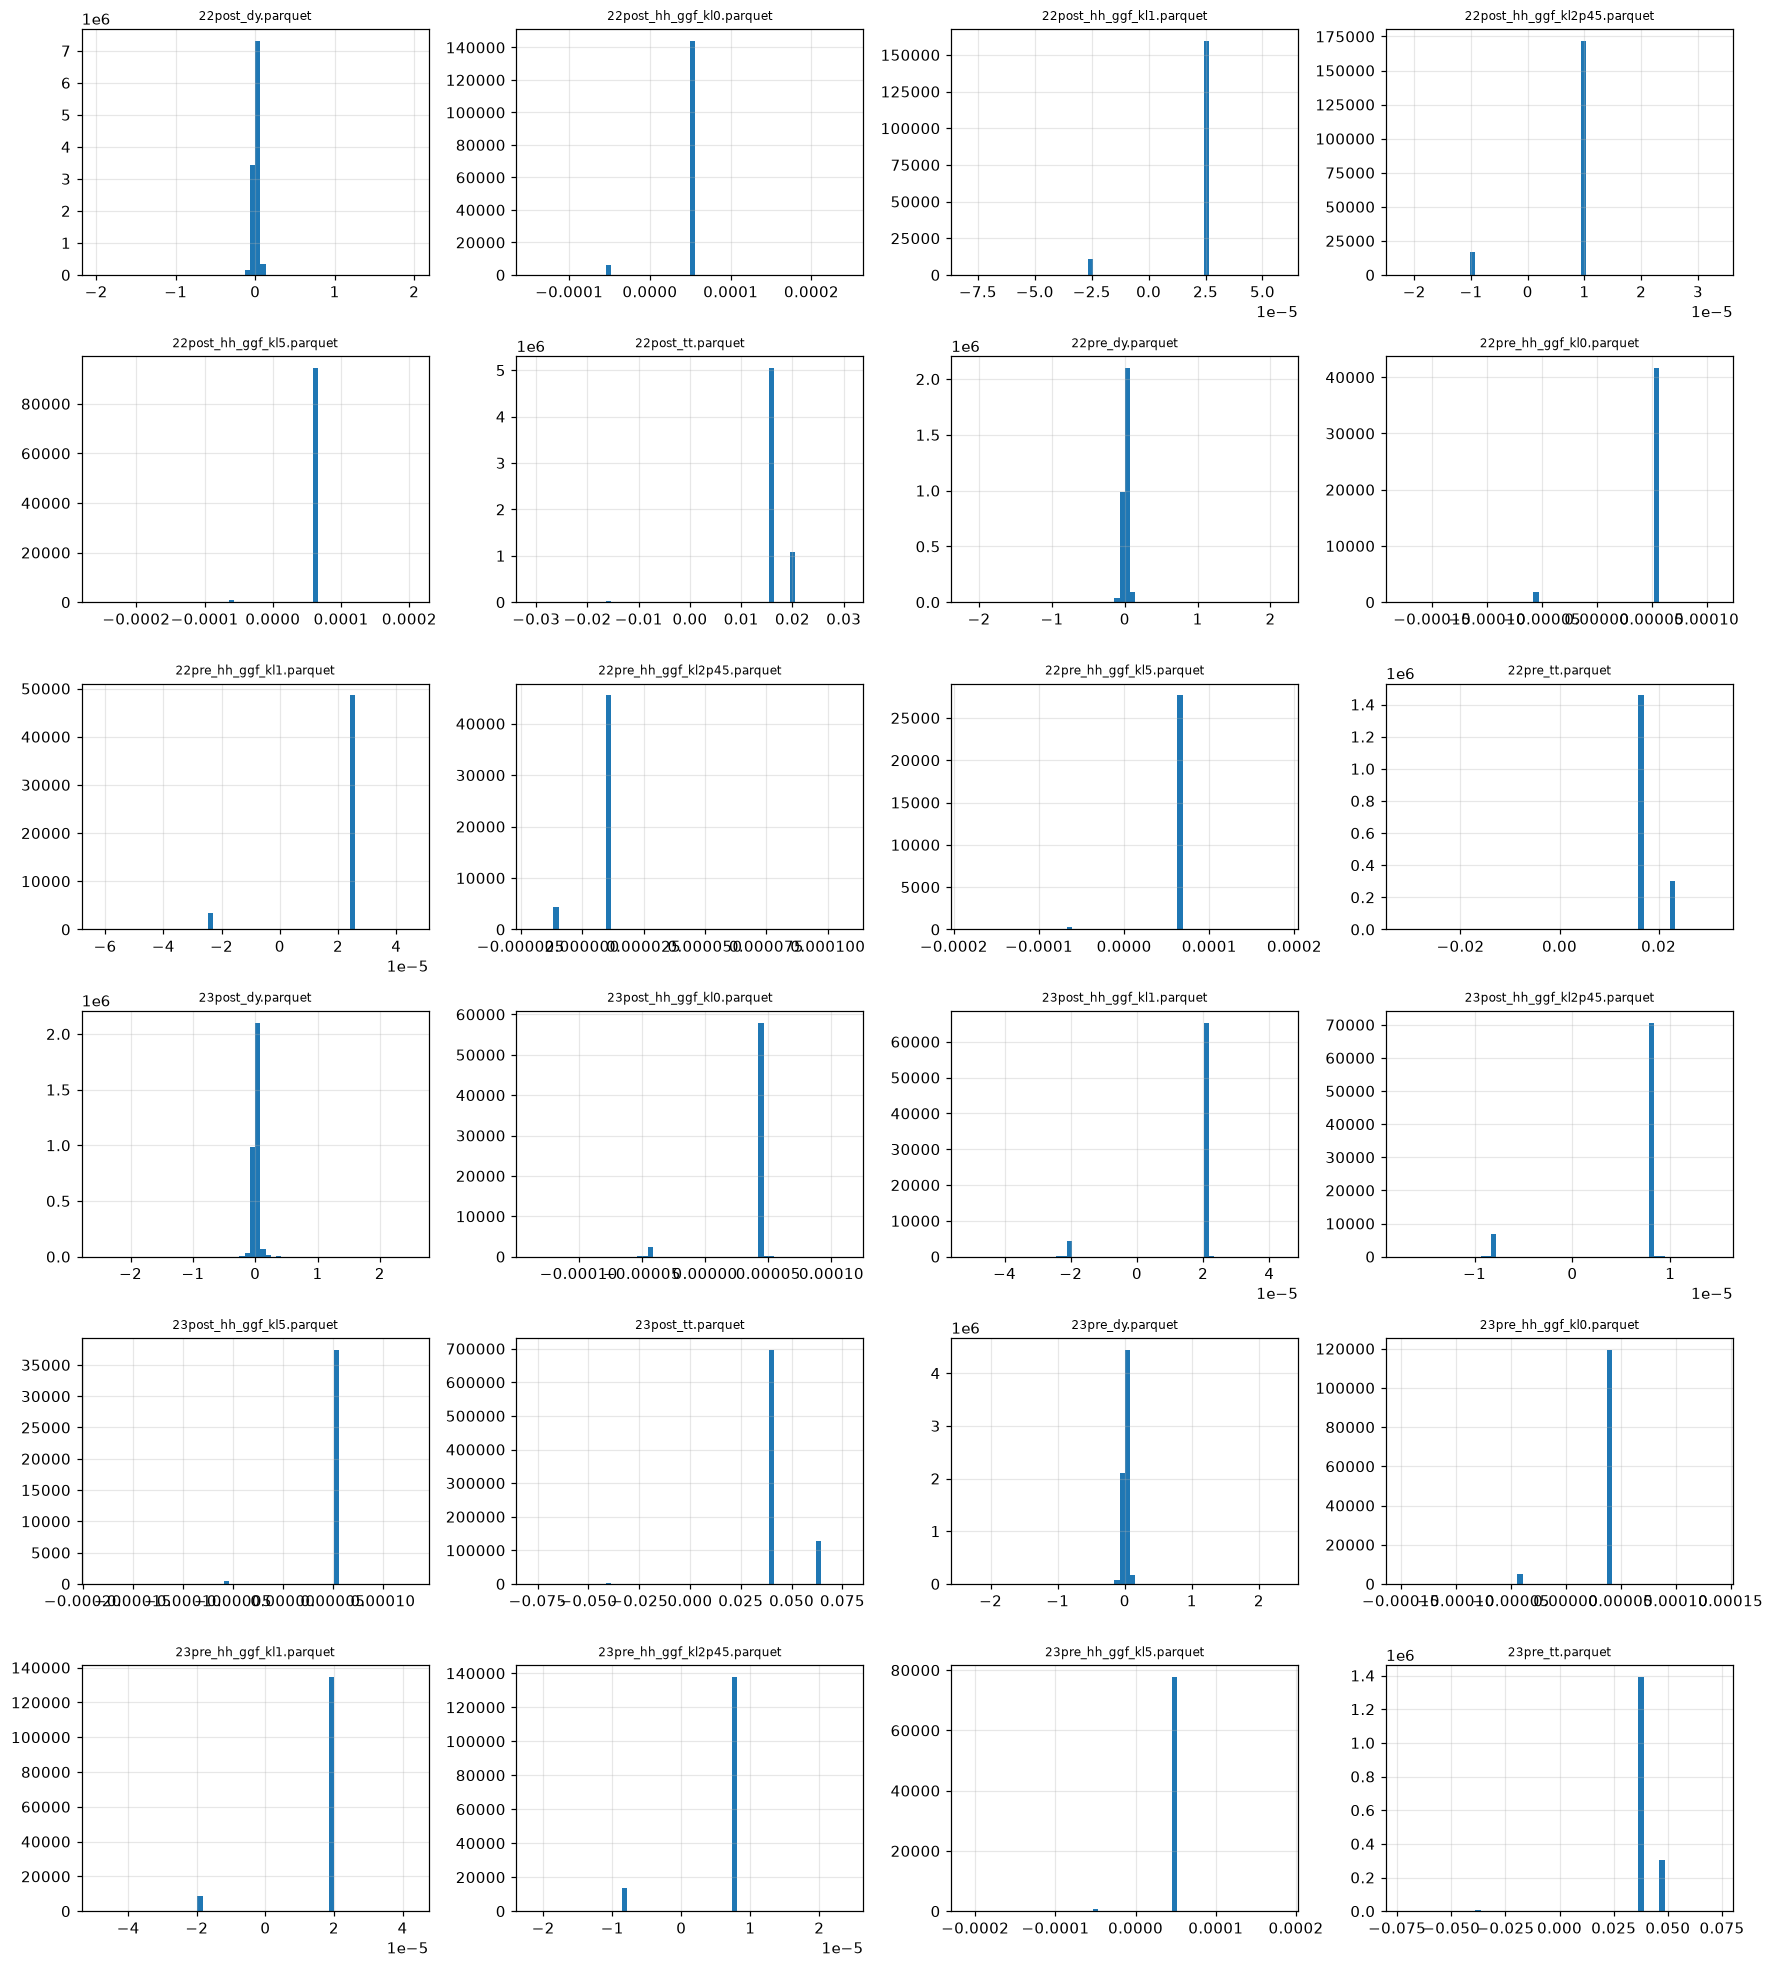

In [3]:
# ============================ Histograma dos pesos (weight) ============================
# Lê só a coluna "weight" de cada parquet e plota o histograma, sem processar mais nada.

files_peek = sorted(PARQUET_DIR.glob("*.parquet"))
assert files_peek, f"Nenhum parquet encontrado em {PARQUET_DIR}"

pesos = {f.name: pq.read_table(f, columns=["normalization_weight"])["normalization_weight"].to_numpy() for f in files_peek}

for nome, w in pesos.items():
    print(f"{nome:32s} soma = {w.sum():.3e}")

ncol = 4
nrow = int(np.ceil(len(files_peek) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow), squeeze=False)
for ax, (nome, w) in zip(axes.flat, pesos.items()):
    ax.hist(w, bins=60, color="tab:blue")
    ax.set_title(nome, fontsize=8)
for ax in axes.flat[len(files_peek):]:
    ax.axis("off")
fig.tight_layout(); plt.show()

del files_peek, pesos

,arquivo,n,soma,media,desvio,min,max,frac_negativo,frac_zero
0,22post_dy.parquet,11255296,6.770e+04,6.015e-03,3.196e-02,-1.984e+00,1.984e+00,31.85%,0.00%
1,22post_hh_ggf_kl0.parquet,150949,7.057e+00,4.675e-05,2.101e-05,-1.457e-04,2.449e-04,4.25%,0.00%
2,22post_hh_ggf_kl1.parquet,171215,3.630e+00,2.120e-05,1.216e-05,-7.977e-05,5.881e-05,6.54%,0.00%
3,22post_hh_ggf_kl2p45.parquet,189577,1.516e+00,7.997e-06,5.634e-06,-2.219e-05,3.341e-05,9.06%,0.00%
4,22post_hh_ggf_kl5.parquet,95647,6.011e+00,6.285e-05,1.418e-05,-2.569e-04,2.052e-04,1.11%,0.00%
5,22post_tt.parquet,6155497,1.002e+05,1.628e-02,2.580e-03,-3.078e-02,3.078e-02,0.34%,0.00%
6,22pre_dy.parquet,3220273,2.030e+04,6.304e-03,3.374e-02,-2.165e+00,2.165e+00,31.88%,0.00%
7,22pre_hh_ggf_kl0.parquet,43745,2.158e+00,4.932e-05,2.271e-05,-1.777e-04,1.097e-04,4.43%,0.00%
8,22pre_hh_ggf_kl1.parquet,52261,1.101e+00,2.106e-05,1.233e-05,-6.261e-05,4.572e-05,6.76%,0.00%
9,22pre_hh_ggf_kl2p45.parquet,50141,4.627e-01,9.228e-06,6.450e-06,-2.029e-05,1.081e-04,8.92%,0.00%


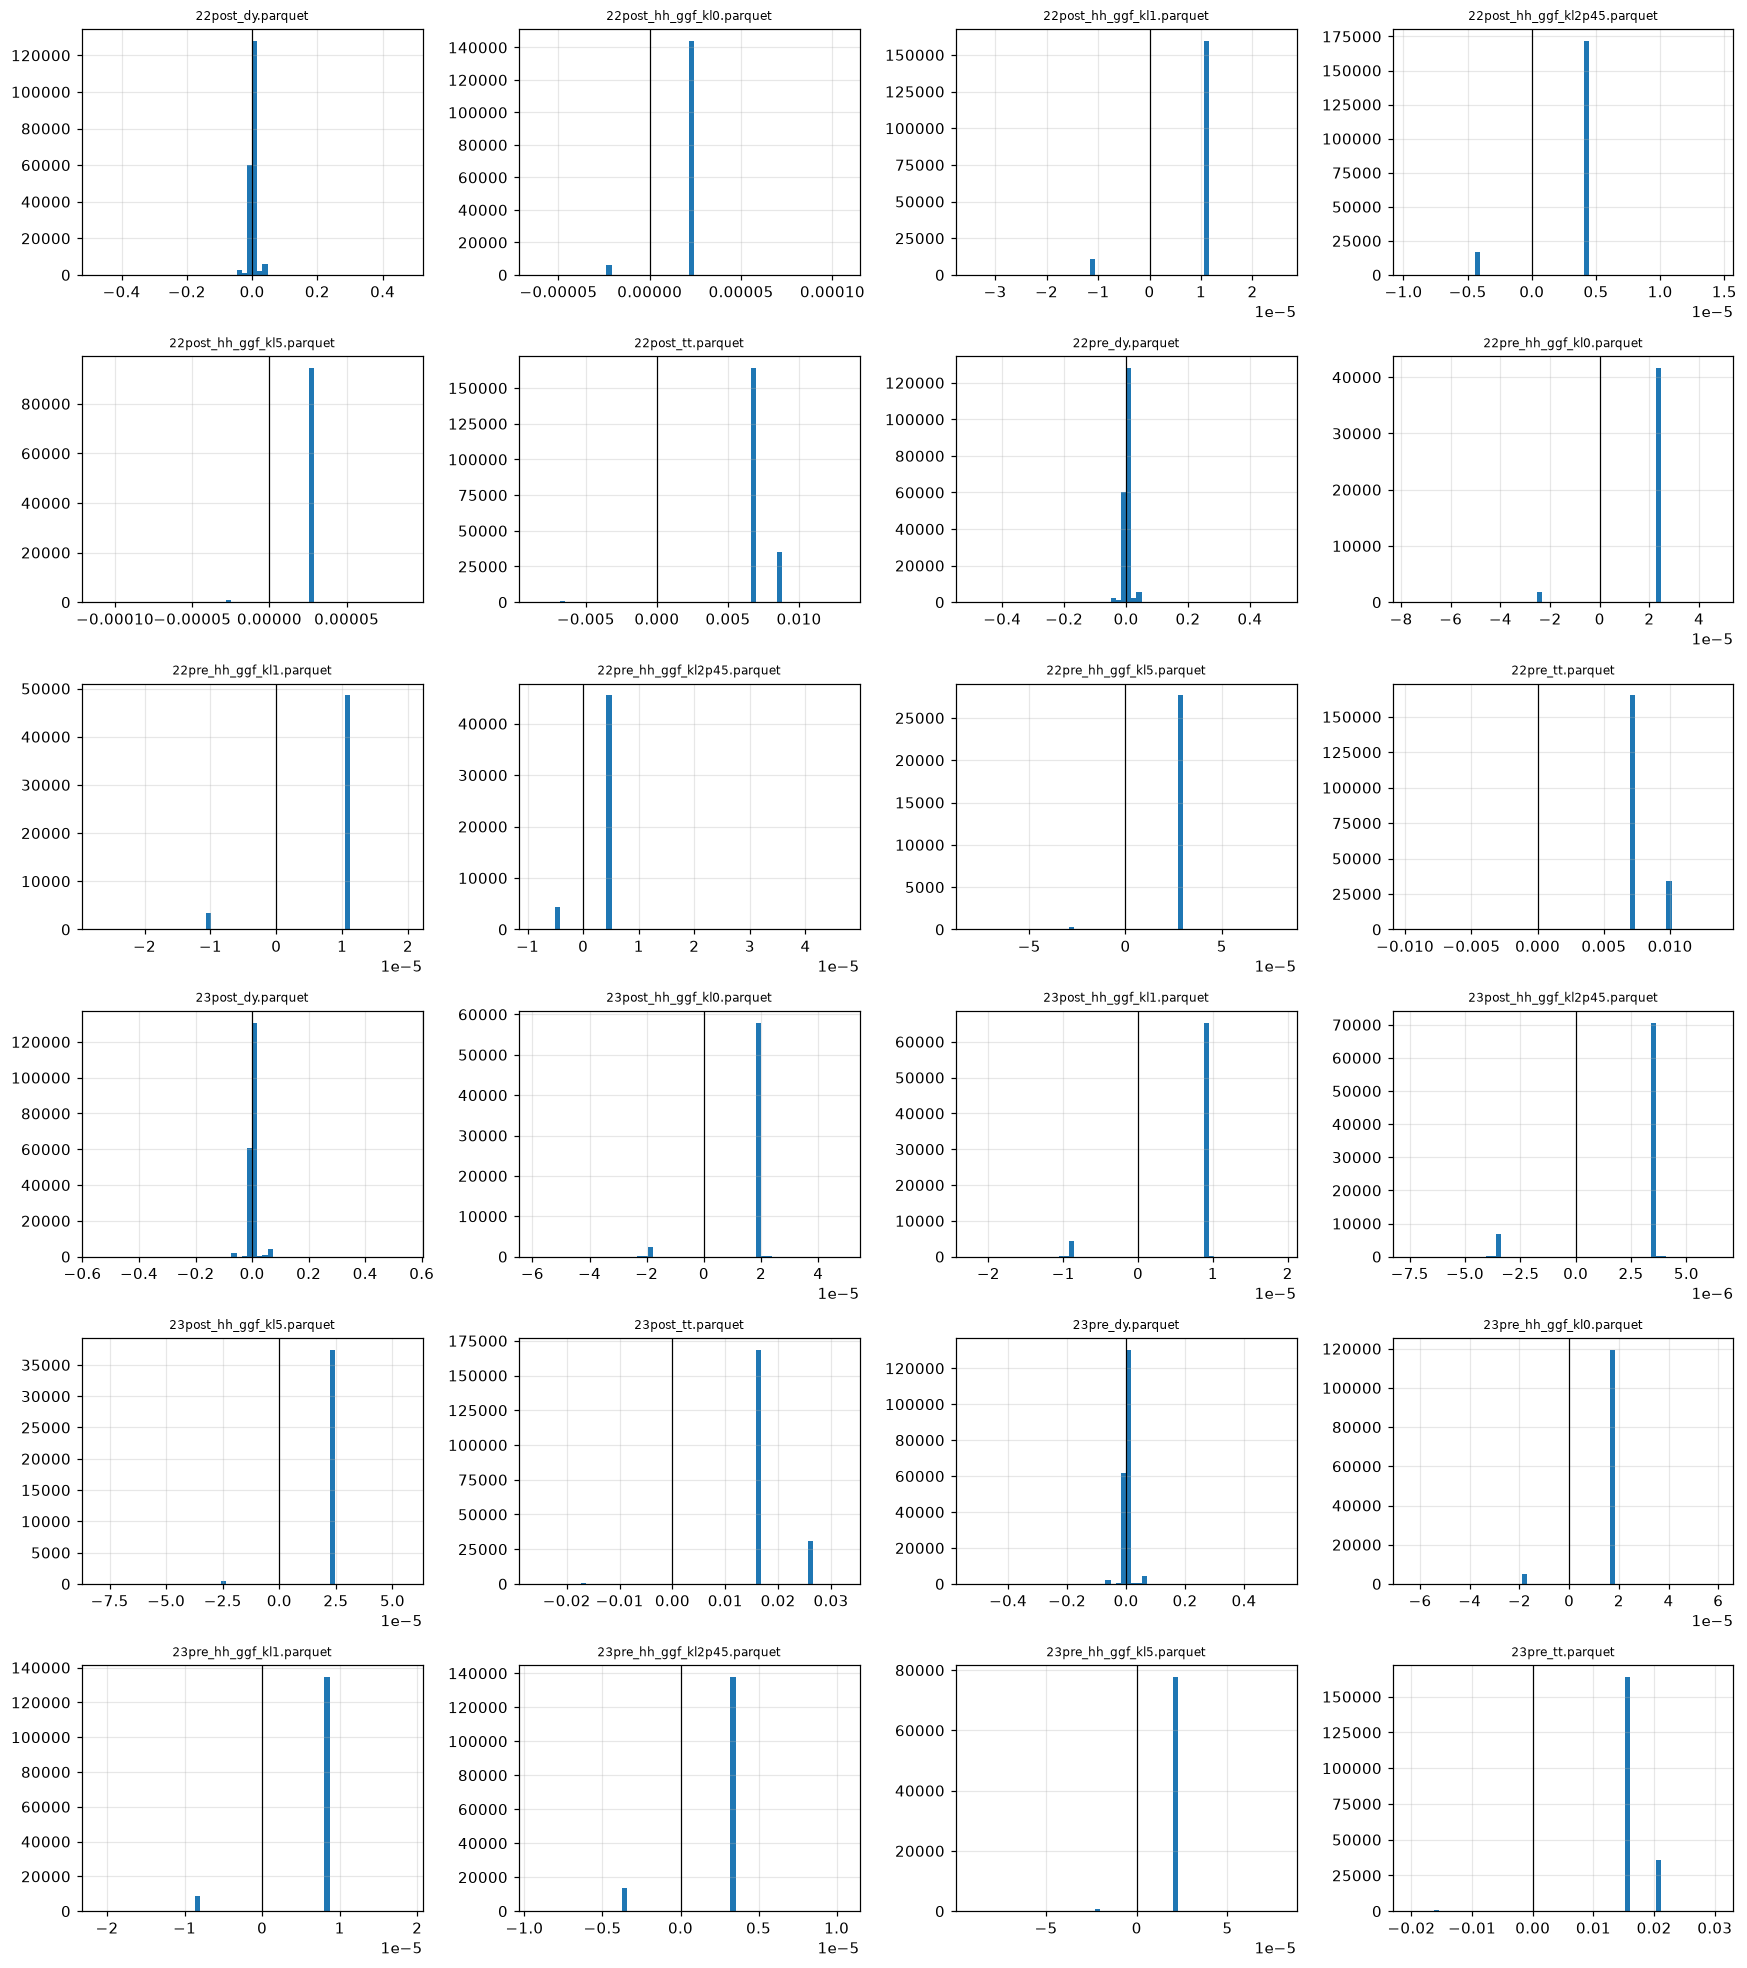

In [4]:
# ============================ Inspeção rápida dos pesos (weight) ============================
# Lê só a coluna "weight" de cada parquet (rápido, sem carregar features) e mostra a
# distribuição por arquivo. Não depende de nada lido depois — lista os parquets aqui mesmo.

files_peek = sorted(PARQUET_DIR.glob("*.parquet"))
assert files_peek, f"Nenhum parquet encontrado em {PARQUET_DIR}"

peso_resumo, amostras_peso = [], {}
rng_peso = np.random.default_rng(SEED)

for f in files_peek:
    w = pq.read_table(f, columns=["normalization_weight"])["normalization_weight"].to_numpy()
    peso_resumo.append(dict(
        arquivo=f.name, n=len(w), soma=w.sum(), media=w.mean(), desvio=w.std(),
        min=w.min(), max=w.max(),
        frac_negativo=(w < 0).mean(), frac_zero=(w == 0).mean(),
    ))
    amostras_peso[f.name] = rng_peso.choice(w, min(len(w), 200_000), replace=False)

peso_resumo = pd.DataFrame(peso_resumo).sort_values("arquivo")
display(peso_resumo.style.format({
    "soma": "{:.3e}", "media": "{:.3e}", "desvio": "{:.3e}", "min": "{:.3e}", "max": "{:.3e}",
    "frac_negativo": "{:.2%}", "frac_zero": "{:.2%}",
}))

# histograma por arquivo: sign(weight) * log10(1 + |weight|)
# (log preserva a forma da cauda sem esconder o sinal; um pico em z=0 é peso ~0)
ncol = 4
nrow = int(np.ceil(len(files_peek) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow), squeeze=False)
for ax, f in zip(axes.flat, files_peek):
    w = amostras_peso[f.name]
    z = np.sign(w) * np.log10(1 + np.abs(w))
    ax.hist(z, bins=60, color="tab:blue")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f.name, fontsize=8)
for ax in axes.flat[len(files_peek):]:
    ax.axis("off")
fig.tight_layout(); plt.show()

del files_peek   # evita confundir com "files", criado depois na Inspeção dos arquivos

Agora conferimos onde o notebook está rodando e o que ele tem disponível (CPUs, memória e GPU). Se a lista de GPUs vier vazia, o treino roda na CPU.

In [5]:
def rss_gb():
    # memória residente do processo (GB)
    try:
        with open("/proc/self/status") as f:
            for line in f:
                if line.startswith("VmRSS"):
                    return int(line.split()[1]) / 1e6
    except Exception:
        pass
    return float("nan")

def mem_limit_gb():
    # limite de memória da sessão (cgroup), se existir
    for p in ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"):
        try:
            v = Path(p).read_text().strip()
            if v.isdigit() and int(v) < (1 << 50):
                return int(v) / 1e9
        except Exception:
            pass
    return float("nan")

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
keras.utils.set_random_seed(SEED)

print("SWAN:", ON_SWAN, "| CPUs:", os.cpu_count(), f"| limite de memória: {mem_limit_gb():.1f} GB | RSS: {rss_gb():.1f} GB")
print("BASE_DIR:", BASE_DIR)
print("GPUs:", gpus if gpus else "nenhuma -> o treino vai rodar na CPU")
if gpus:
    try:
        print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
                             capture_output=True, text=True, timeout=20).stdout.strip())
    except Exception:
        pass

SWAN: True | CPUs: 28 | limite de memória: 34.4 GB | RSS: 1.3 GB
BASE_DIR: /eos/user/l/lefrankl/pNN_hh2bbtautau
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Tesla T4, 15360 MiB, 580.159.04


## Features

Comente (`#`) as que **não** quiser usar. Não coloque `kappa_lambda`, `kt`, `weight`, `mc_weight`, `label`, `process_id`, `sample` nem `source_file` aqui:
o $\kappa_\lambda$ é adicionado automaticamente como última entrada da rede, e as demais colunas não são features.

As features são: a **MET** (componentes e covariância), os quadrivetores $(E, p_x, p_y, p_z)$ dos dois taus visíveis, dos dois b-jets e do fat jet, os sistemas compostos (H→ττ, H→bb e combinações), os *tags* dos b-jets e informações do evento (tipo do par, modos de decaimento, cargas e flags `has_*`).

In [6]:
FEATURES = [
    # MET
    "reg_dnn_moe_met_px",
    "reg_dnn_moe_met_py",
    "reg_dnn_moe_met_cov00",
    "reg_dnn_moe_met_cov01",
    "reg_dnn_moe_met_cov11",

    # Visible tau 1
    "reg_dnn_moe_vis_tau1_e",
    "reg_dnn_moe_vis_tau1_px",
    "reg_dnn_moe_vis_tau1_py",
    "reg_dnn_moe_vis_tau1_pz",

    # Visible tau 2
    "reg_dnn_moe_vis_tau2_e",
    "reg_dnn_moe_vis_tau2_px",
    "reg_dnn_moe_vis_tau2_py",
    "reg_dnn_moe_vis_tau2_pz",

    # b-jet 1
    "reg_dnn_moe_bjet1_e",
    "reg_dnn_moe_bjet1_px",
    "reg_dnn_moe_bjet1_py",
    "reg_dnn_moe_bjet1_pz",
    "reg_dnn_moe_bjet1_tag_b",
    "reg_dnn_moe_bjet1_tag_cvsb",
    "reg_dnn_moe_bjet1_tag_cvsl",
    "reg_dnn_moe_bjet1_hhbtag",

    # b-jet 2
    "reg_dnn_moe_bjet2_e",
    "reg_dnn_moe_bjet2_px",
    "reg_dnn_moe_bjet2_py",
    "reg_dnn_moe_bjet2_pz",
    "reg_dnn_moe_bjet2_tag_b",
    "reg_dnn_moe_bjet2_tag_cvsb",
    "reg_dnn_moe_bjet2_tag_cvsl",
    "reg_dnn_moe_bjet2_hhbtag",

    # Fat jet
    "reg_dnn_moe_fatjet_e",
    "reg_dnn_moe_fatjet_px",
    "reg_dnn_moe_fatjet_py",
    "reg_dnn_moe_fatjet_pz",

    # Hadronic tau-tau system
    "reg_dnn_moe_htt_e",
    "reg_dnn_moe_htt_px",
    "reg_dnn_moe_htt_py",
    "reg_dnn_moe_htt_pz",

    # Higgs -> bb system
    "reg_dnn_moe_hbb_e",
    "reg_dnn_moe_hbb_px",
    "reg_dnn_moe_hbb_py",
    "reg_dnn_moe_hbb_pz",

    # htt + hbb system
    "reg_dnn_moe_htthbb_e",
    "reg_dnn_moe_htthbb_px",
    "reg_dnn_moe_htthbb_py",
    "reg_dnn_moe_htthbb_pz",

    # htt + fat jet system
    "reg_dnn_moe_httfatjet_e",
    "reg_dnn_moe_httfatjet_px",
    "reg_dnn_moe_httfatjet_py",
    "reg_dnn_moe_httfatjet_pz",

    # Event information
    "reg_dnn_moe_pair_type",
    "reg_dnn_moe_dm1",
    "reg_dnn_moe_dm2",
    "reg_dnn_moe_vis_tau1_charge",
    "reg_dnn_moe_vis_tau2_charge",
    "reg_dnn_moe_has_jet_pair",
    "reg_dnn_moe_has_fatjet",
]

print(len(FEATURES), "features selecionadas")

56 features selecionadas


## Inspeção dos arquivos

Antes de carregar qualquer coisa, listamos os parquets, conferimos se as colunas existem e estimamos a memória necessária.
O nome do arquivo segue `<era>_<processo>.parquet` (ex.: `22pre_hh_ggf_kl2p45.parquet`), com era ∈ {22pre, 22post, 23pre, 23post}.

In [7]:
assert PARQUET_DIR.exists(), f"Pasta não encontrada: {PARQUET_DIR}\nConfira EOS_LETTER / EOS_USER (e se o EOS está montado)."
files = sorted(PARQUET_DIR.glob("*.parquet"))
FILE_RE = re.compile(r"^(?P<era>\d{2}(?:pre|post))_(?P<proc>.+)\.parquet$")

# colunas necessárias existem?
schema = pq.read_schema(files[0])
needed = FEATURES + ["kappa_lambda", "normalization_weight", "label"]
missing = [c for c in needed if c not in schema.names]
assert not missing, f"Colunas ausentes no parquet: {missing}"
assert not set(FEATURES) & {"kappa_lambda", "kt", "weight", "normalization_weight", "mc_weight", "label", "process_id"}, "Remova colunas não-feature de FEATURES"

# features inteiras (pair_type, dm1, dm2, cargas, has_*) não serão padronizadas
INT_FEATURES = [f for f in FEATURES if pa.types.is_integer(schema.field(f).type)]
print("Features inteiras (ficam sem padronizar):", INT_FEATURES)

# inventário
inv = pd.DataFrame([dict(arquivo=f.name, era=FILE_RE.match(f.name)["era"], processo=FILE_RE.match(f.name)["proc"],
                         n_eventos=pq.read_metadata(f).num_rows) for f in files])
display(inv)
print(f"{len(files)} arquivos | {inv['n_eventos'].sum():,d} eventos no total")

LOCAL_DIR.mkdir(parents=True, exist_ok=True)
(LOCAL_DIR / "plots").mkdir(exist_ok=True)

Features inteiras (ficam sem padronizar): ['reg_dnn_moe_pair_type', 'reg_dnn_moe_dm1', 'reg_dnn_moe_dm2', 'reg_dnn_moe_vis_tau1_charge', 'reg_dnn_moe_vis_tau2_charge', 'reg_dnn_moe_has_jet_pair', 'reg_dnn_moe_has_fatjet']


,arquivo,era,processo,n_eventos
0,22post_dy.parquet,22post,dy,11255296
1,22post_hh_ggf_kl0.parquet,22post,hh_ggf_kl0,150949
2,22post_hh_ggf_kl1.parquet,22post,hh_ggf_kl1,171215
3,22post_hh_ggf_kl2p45.parquet,22post,hh_ggf_kl2p45,189577
4,22post_hh_ggf_kl5.parquet,22post,hh_ggf_kl5,95647
5,22post_tt.parquet,22post,tt,6155497
6,22pre_dy.parquet,22pre,dy,3220273
7,22pre_hh_ggf_kl0.parquet,22pre,hh_ggf_kl0,43745
8,22pre_hh_ggf_kl1.parquet,22pre,hh_ggf_kl1,52261
9,22pre_hh_ggf_kl2p45.parquet,22pre,hh_ggf_kl2p45,50141


24 arquivos | 36,450,158 eventos no total


## Leitura dos dados

Agora usamos **todos** os eventos de DY e TT (dezenas de milhões). Para isso nada grande vive na RAM:
1. contamos antes quantos eventos vamos usar (`MAX_BKG_PER_FILE = None` → todos);
2. criamos os arrays de features como **`np.memmap` em disco** (`MEMMAP_DIR`); só os vetores 1D (pesos, labels, kl, divisão) ficam na memória;
3. lemos cada parquet em blocos de `CHUNK_SIZE` linhas e escrevemos cada bloco direto no array em disco;
4. a padronização, as predições e o treino também andam em chunks (o treino lê *batches* do disco via `keras.utils.Sequence`).

Se `MAX_BKG_PER_FILE` for um número, o fundo é subamostrado e seus pesos são multiplicados por `n_original / n_usado`, para manter a soma de pesos (antes da renormalização sinal/fundo).
Cada arquivo também recebe, aqui, sua divisão treino/val/teste (aleatória por evento). Arquivos de `HOLDOUT_KL` vão inteiros para o teste.

Os parâmetros que controlam a leitura:

- **`SPLIT`**: divisão treino/validação/teste (aleatória por evento, dentro de cada arquivo).
- **`MAX_BKG_PER_FILE`**: `None` = todos os eventos de DY/TT. Um número limita cada arquivo de fundo (o peso é compensado).
- **`HOLDOUT_KL`**: pontos de MC que **não** entram no treino, só no teste. Serve para medir a interpolação (ver o exercício opcional no fim). Comece com `[]`.
- **`CHUNK_SIZE`**: nº de eventos por bloco (leitura, padronização, predição). Diminua se faltar memória.
- **`MEMMAP_DIR`**: onde ficam os arrays grandes em disco. Fica **fora** de `LOCAL_DIR` de propósito, para não ser copiado para o EOS a cada época. Precisa de espaço livre de ~`2 × N × F × 4` bytes (a célula seguinte mostra a estimativa).
- **`CLASS_NAMES`**: nomes das classes (0 = DY, 1 = TT, 2 = HH).

In [8]:
# ============================ Dados ============================
SPLIT            = dict(train=0.70, val=0.15, test=0.15)   # divisão aleatória por evento, dentro de cada arquivo
MAX_BKG_PER_FILE = None         # None = TODOS os eventos de DY/TT (lidos em chunks e guardados em disco, ver MEMMAP_DIR)
HOLDOUT_KL       = []           # ex.: [2.45] -> ponto de MC usado só no teste

CHUNK_SIZE = 500_000            # eventos por bloco ao ler / padronizar / predizer (diminua se faltar memória)
MEMMAP_DIR = Path(os.environ.get("TMPDIR", "/tmp")) / f"pnn_{RUN_NAME}_memmap"   # arrays grandes em disco (fora de LOCAL_DIR: não vai ao EOS)
MEMMAP_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = {0: "DY", 1: "TT", 2: "HH"}

In [9]:
LOAD_COLS   = FEATURES + ["kappa_lambda", "normalization_weight", "label"]
SPLIT_NAMES = ["train", "val", "test"]
assert abs(sum(SPLIT.values()) - 1) < 1e-9

def n_usado(nome, n):
    eh_sinal = "_hh_" in nome
    return n if (eh_sinal or not MAX_BKG_PER_FILE) else min(n, MAX_BKG_PER_FILE)

inv["n_usado"] = [n_usado(a, n) for a, n in zip(inv["arquivo"], inv["n_eventos"])]
N, F = int(inv["n_usado"].sum()), len(FEATURES)
disk_gb  = N * (2 * F + 1) * 4 / 1e9          # X bruto (F) + X padronizado nos 3 conjuntos (F+1)
ram_gb   = N * 50 / 1e9                       # só vetores 1D: W, Y, KL, SRC, SPLIT_ID, ...
free_gb, lim = shutil.disk_usage(MEMMAP_DIR).free / 1e9, mem_limit_gb()
print(f"Eventos usados: {N:,d} | features em disco (memmap): ~{disk_gb:.1f} GB (livre em {MEMMAP_DIR}: {free_gb:.0f} GB)")
print(f"RAM estimada (vetores 1D + 1 chunk de {CHUNK_SIZE:,d} eventos): ~{ram_gb + 3 * CHUNK_SIZE * F * 4 / 1e9:.1f} GB (limite da sessão: {lim:.1f} GB)")
if disk_gb > 0.9 * free_gb:
    print("[AVISO] pode faltar disco em MEMMAP_DIR: aponte MEMMAP_DIR para um volume maior ou use MAX_BKG_PER_FILE.")
if lim == lim and ram_gb > 0.5 * lim:
    print("[AVISO] os vetores 1D já ocupam muita RAM: reduza CHUNK_SIZE / MAX_BKG_PER_FILE ou inicie o SWAN com mais memória.")

# arrays finais (um elemento por evento). X fica em DISCO (memmap); o resto cabe na RAM.
X        = np.lib.format.open_memmap(MEMMAP_DIR / "X_raw.npy", mode="w+", dtype=np.float32, shape=(N, F))   # features
W        = np.empty(N, np.float64)        # coluna 'normalization_weight' (peso oficial, usado como está)
Y        = np.empty(N, np.int8)           # label: 0=DY, 1=TT, 2=HH
KL_TRUE  = np.empty(N, np.float64)        # kappa_lambda (NaN nos fundos)
SRC      = np.empty(N, np.int16)          # índice do arquivo de origem
SPLIT_ID = np.empty(N, np.int8)           # 0=treino, 1=validação, 2=teste

Eventos usados: 36,450,158 | features em disco (memmap): ~16.5 GB (livre em /tmp/pnn_pnn_v1_memmap: 67 GB)
RAM estimada (vetores 1D + 1 chunk de 500,000 eventos): ~2.2 GB (limite da sessão: 34.4 GB)


In [10]:
rng = np.random.default_rng(SEED)
pos, t0 = 0, time.time()

for i, (path, n_orig, n_use) in enumerate(zip(files, inv["n_eventos"], inv["n_usado"])):
    subamostra = n_use < n_orig
    keep = np.sort(rng.choice(n_orig, n_use, replace=False)) if subamostra else None   # só se MAX_BKG_PER_FILE limitar
    start, off = pos, 0

    for batch in pq.ParquetFile(path).iter_batches(batch_size=CHUNK_SIZE, columns=LOAD_COLS):
        if subamostra:
            lo, hi = np.searchsorted(keep, [off, off + batch.num_rows])
            loc = keep[lo:hi] - off
            off += batch.num_rows
            if len(loc) == 0:
                continue
            df = batch.to_pandas().iloc[loc]
        else:
            df = batch.to_pandas()                 # arquivo inteiro, um chunk por vez
        k = len(df)
        X[pos:pos + k]       = df[FEATURES].to_numpy(np.float32)     # escreve direto no memmap (disco)
        W[pos:pos + k]       = df["normalization_weight"].to_numpy(np.float64)
        Y[pos:pos + k]       = df["label"].to_numpy(np.int8)
        KL_TRUE[pos:pos + k] = df["kappa_lambda"].to_numpy(np.float64)
        pos += k
        del df

    sl = slice(start, pos)
    assert pos - start == n_use, f"{path.name}: lidos {pos - start}, esperados {n_use}"
    assert len(np.unique(Y[sl])) == 1, f"{path.name}: mais de um label"
    if subamostra:
        W[sl] *= n_orig / n_use          # só roda se MAX_BKG_PER_FILE limitar o fundo (compensa a subamostragem)
    SRC[sl] = i

    # divisão treino/val/teste (sorteio em blocos, para não criar um vetor aleatório gigante)
    eh_holdout = (Y[start] == 2) and bool(np.isclose(KL_TRUE[start], HOLDOUT_KL).any())
    if eh_holdout:
        SPLIT_ID[sl] = 2                 # ponto de MC reservado só para o teste
    else:
        for a in range(start, pos, 5_000_000):
            b = min(a + 5_000_000, pos)
            SPLIT_ID[a:b] = np.digitize(rng.random(b - a), [SPLIT["train"], SPLIT["train"] + SPLIT["val"]])

    print(f"[{i+1:2d}/{len(files)}] {path.name:32s} {n_use:>11,d} eventos ({time.time()-t0:.0f}s, RSS {rss_gb():.1f} GB)")

assert pos == N
X.flush()

[ 1/24] 22post_dy.parquet                 11,255,296 eventos (9s, RSS 6.3 GB)
[ 2/24] 22post_hh_ggf_kl0.parquet            150,949 eventos (9s, RSS 6.3 GB)
[ 3/24] 22post_hh_ggf_kl1.parquet            171,215 eventos (9s, RSS 6.3 GB)
[ 4/24] 22post_hh_ggf_kl2p45.parquet         189,577 eventos (9s, RSS 6.4 GB)
[ 5/24] 22post_hh_ggf_kl5.parquet             95,647 eventos (10s, RSS 6.4 GB)
[ 6/24] 22post_tt.parquet                  6,155,497 eventos (14s, RSS 8.3 GB)
[ 7/24] 22pre_dy.parquet                   3,220,273 eventos (17s, RSS 9.1 GB)
[ 8/24] 22pre_hh_ggf_kl0.parquet              43,745 eventos (17s, RSS 9.1 GB)
[ 9/24] 22pre_hh_ggf_kl1.parquet              52,261 eventos (17s, RSS 9.1 GB)
[10/24] 22pre_hh_ggf_kl2p45.parquet           50,141 eventos (17s, RSS 9.2 GB)
[11/24] 22pre_hh_ggf_kl5.parquet              28,044 eventos (17s, RSS 9.2 GB)
[12/24] 22pre_tt.parquet                   1,765,475 eventos (19s, RSS 9.6 GB)
[13/24] 23post_dy.parquet                  3,207,647 eve

Um resumo por arquivo (número de eventos usados, soma dos pesos e fração de pesos negativos) e o tamanho de cada conjunto:

In [11]:
# resumo por arquivo
starts = np.r_[0, np.cumsum(inv["n_usado"])[:-1]]
inv["label"]               = Y[starts]
inv["kl"]                  = KL_TRUE[starts]
inv["soma_pesos"]          = np.bincount(SRC, weights=W, minlength=len(files))
inv["frac_peso_negativo"]  = np.bincount(SRC, weights=(W < 0).astype(float), minlength=len(files)) / inv["n_usado"]
display(inv)

for k, s in enumerate(SPLIT_NAMES):
    sel = SPLIT_ID == k
    print(f"{s:5s}: {sel.sum():>10,d} eventos | DY, TT, HH = {np.bincount(Y[sel], minlength=3)}")

,arquivo,era,processo,n_eventos,n_usado,label,kl,soma_pesos,frac_peso_negativo
0,22post_dy.parquet,22post,dy,11255296,11255296,0,NaN,67697.387876,0.318547
1,22post_hh_ggf_kl0.parquet,22post,hh_ggf_kl0,150949,150949,2,0.00,7.056514,0.042471
2,22post_hh_ggf_kl1.parquet,22post,hh_ggf_kl1,171215,171215,2,1.00,3.629935,0.065409
3,22post_hh_ggf_kl2p45.parquet,22post,hh_ggf_kl2p45,189577,189577,2,2.45,1.516015,0.090560
4,22post_hh_ggf_kl5.parquet,22post,hh_ggf_kl5,95647,95647,2,5.00,6.011237,0.011124
5,22post_tt.parquet,22post,tt,6155497,6155497,1,NaN,100232.626759,0.003400
6,22pre_dy.parquet,22pre,dy,3220273,3220273,0,NaN,20301.576640,0.318825
7,22pre_hh_ggf_kl0.parquet,22pre,hh_ggf_kl0,43745,43745,2,0.00,2.157669,0.044325
8,22pre_hh_ggf_kl1.parquet,22pre,hh_ggf_kl1,52261,52261,2,1.00,1.100837,0.067565
9,22pre_hh_ggf_kl2p45.parquet,22pre,hh_ggf_kl2p45,50141,50141,2,2.45,0.462722,0.089188


train: 25,515,761 eventos | DY, TT, HH = [17134442  7311402  1069917]
val  :  5,468,410 eventos | DY, TT, HH = [3669633 1569237  229540]
test :  5,465,987 eventos | DY, TT, HH = [3670057 1566673  229257]


## Exploração das distribuições

Distribuições (ponderadas por `normalization_weight`, normalizadas a área 1) de algumas features por classe, num subconjunto do treino.
Serve para checar se os dados fazem sentido (unidades, valores-marcador como -999, etc.).

> **Dica:** mude `PLOT_FEATURES` para ver outras variáveis. Se aparecer um pico estranho em um valor fixo (ex.: -999), coloque-o em `MISSING_VALUES` (na seção *Padronização e conjuntos finais*) e rode o notebook de novo.

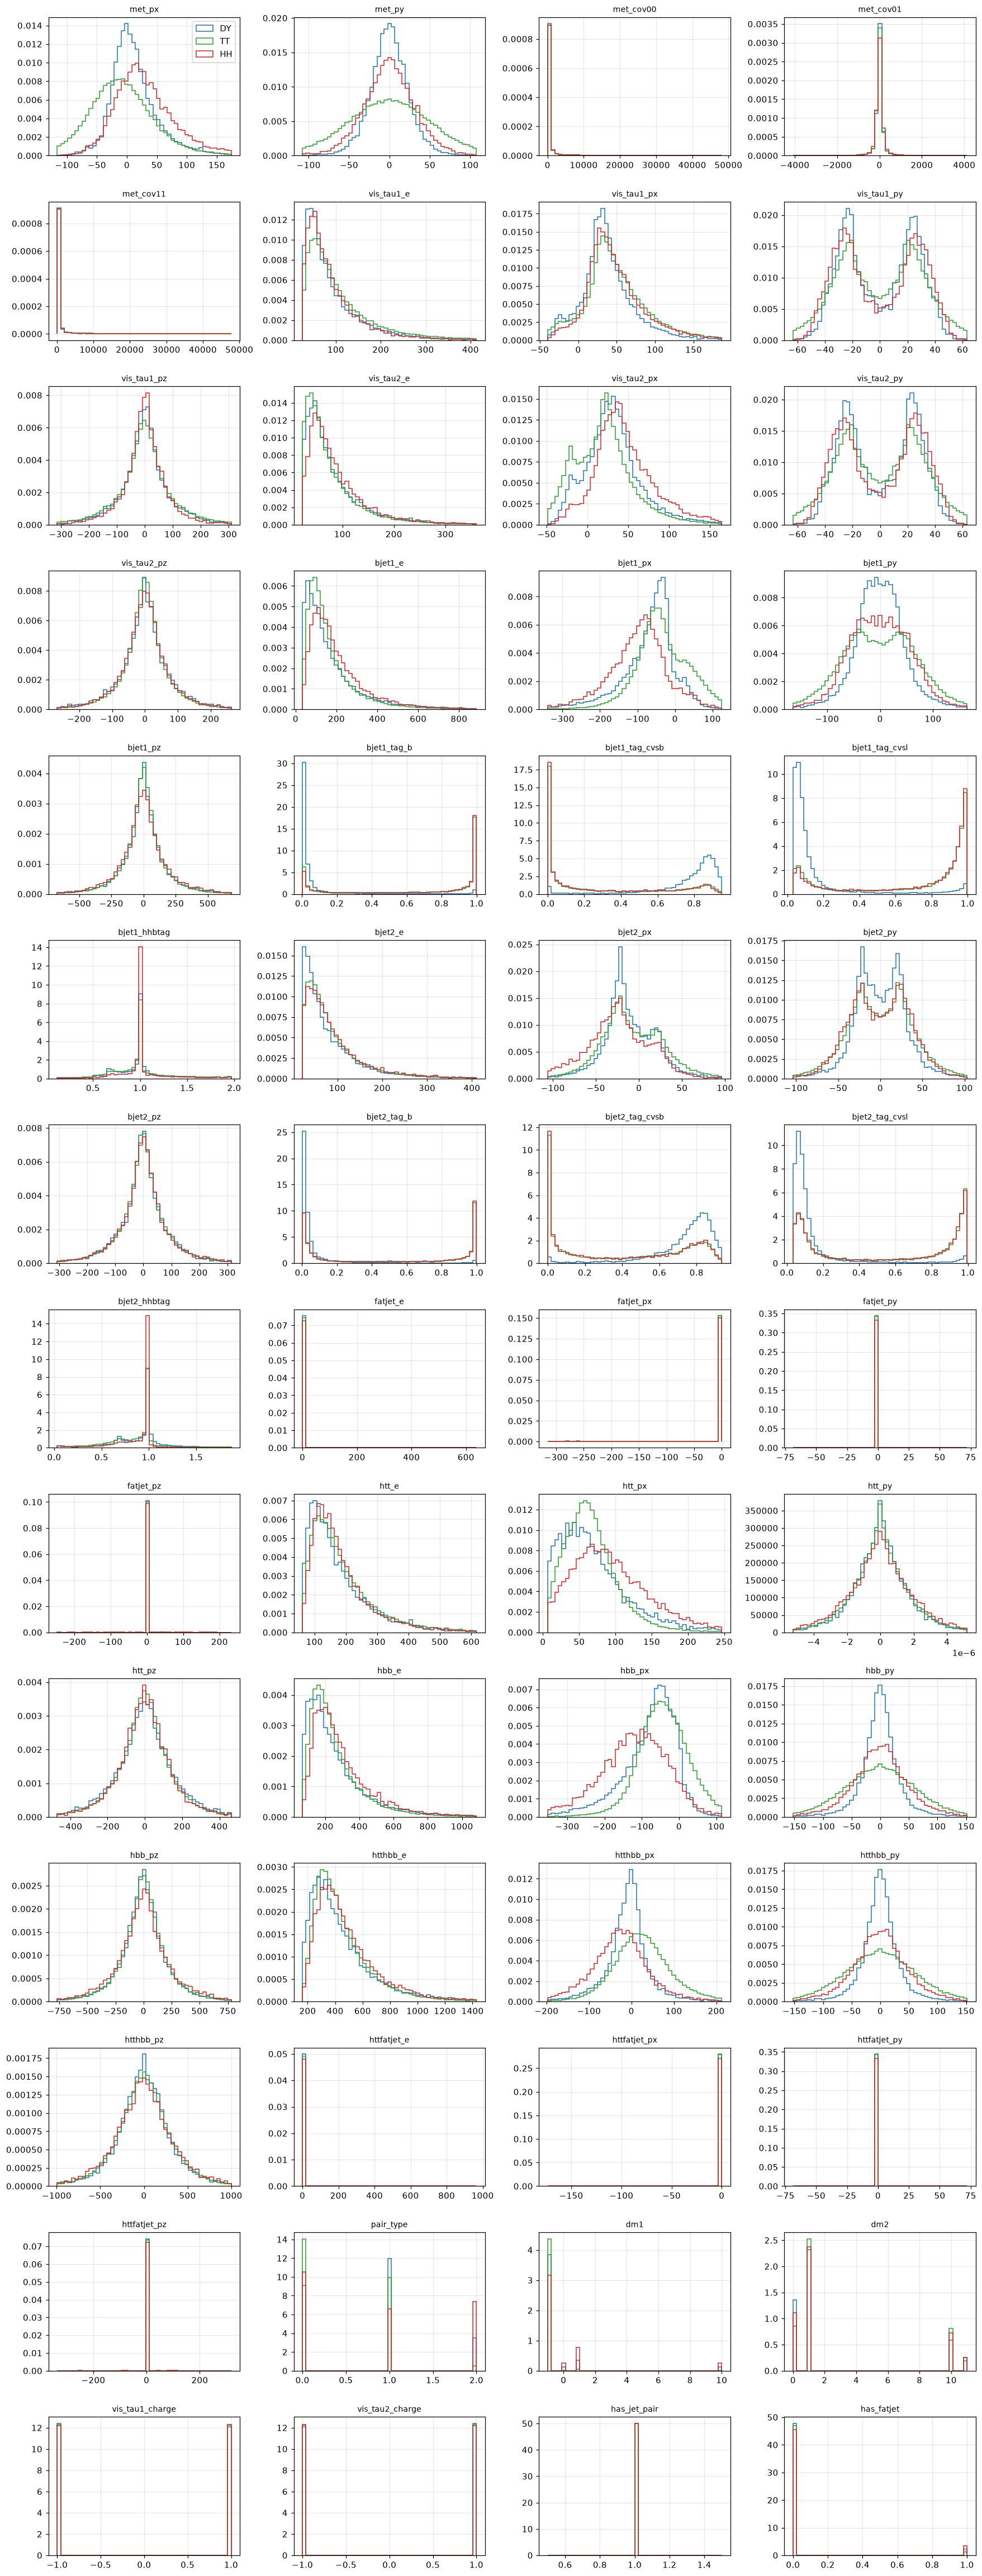

In [12]:
PLOT_FEATURES = FEATURES[:56]                  # <-- escolha quais mostrar
cores = {0: "tab:blue", 1: "tab:green", 2: "tab:red"}

idx = np.flatnonzero(SPLIT_ID == 0)
idx = np.sort(rng.choice(idx, min(400_000, len(idx)), replace=False))
Xp = np.asarray(X[idx])                         # lê do disco só este subconjunto (uma vez)

ncol = 4
nrow = int(np.ceil(len(PLOT_FEATURES) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow), squeeze=False)
for ax, f in zip(axes.flat, PLOT_FEATURES):
    xs = Xp[:, FEATURES.index(f)]
    ok = np.isfinite(xs)
    lo, hi = np.percentile(xs[ok], [1, 99])
    bins = np.linspace(lo, hi, 50) if hi > lo else 50
    for c in (0, 1, 2):
        m = ok & (Y[idx] == c)
        if m.any():
            ax.hist(xs[m], bins=bins, weights=W[idx][m], density=True,   # peso físico com sinal
                    histtype="step", color=cores[c], label=CLASS_NAMES[c])
    ax.set_title(f.replace("reg_dnn_moe_", ""), fontsize=9)
for ax in axes.flat[len(PLOT_FEATURES):]:
    ax.axis("off")
axes.flat[0].legend()
fig.tight_layout(); plt.show()

## Recap: como funciona uma pNN

**O problema.** Na produção de HH por fusão de glúons, o diagrama "triângulo" (proporcional a $\kappa_\lambda$) interfere com o "caixa" (independente de $\kappa_\lambda$). Por isso a cinemática do sinal muda com $\kappa_\lambda$. Um classificador treinado só com sinal de $\kappa_\lambda = 1$ não é o melhor possível para outros valores, e treinar uma rede por hipótese é caro e só cobre os valores para os quais existe MC.

**A ideia (Baldi et al., 2016).** Tratar o parâmetro como uma feature a mais. Sejam $x \in \mathbb{R}^{F}$ as features do evento e $\theta \equiv \kappa_\lambda$ o parâmetro. Em vez de aprender $p(c \mid x)$, a pNN aprende uma função de **dois** argumentos:

$$
f_c(x, \theta) \;\approx\; p(c \mid x, \theta), \qquad c \in \{\mathrm{DY},\ \mathrm{TT},\ \mathrm{HH}\}
$$

Um classificador comum é o caso particular em que $\theta$ é fixo.

**O que a rede calcula.** A rede é um MLP cuja entrada é o vetor das features e do parâmetro, todos padronizados (aqui $\tilde{\cdot}$ indica "padronizado com a média e o desvio do treino"):

$$
h_0 = \big[\tilde{x}_1, \dots, \tilde{x}_F,\ \tilde{\theta}\big], \qquad
h_{l+1} = \mathrm{ReLU}\big(W_l h_l + b_l\big), \qquad
f(x,\theta) = \mathrm{softmax}\big(W_L h_L + b_L\big)
$$

(com `Dropout` entre as camadas). A saída são três probabilidades, $f_{\mathrm{DY}}, f_{\mathrm{TT}}, f_{\mathrm{HH}}$, que somam 1.

**Por que isso faz sentido.** Pela regra de Bayes,

$$
p(\mathrm{HH} \mid x, \theta) = \frac{p(x \mid \mathrm{HH}, \theta)\, p(\mathrm{HH} \mid \theta)}{\sum_{c} p(x \mid c, \theta)\, p(c \mid \theta)}
$$

Se as classes forem balanceadas para cada $\theta$, ou seja $p(c \mid \theta) = 1/3$, isso vira

$$
p(\mathrm{HH} \mid x, \theta) = \frac{p(x \mid \mathrm{HH}, \theta)}{p(x \mid \mathrm{HH}, \theta) + p(x \mid \mathrm{DY}) + p(x \mid \mathrm{TT})}
$$

Os fundos não dependem de $\kappa_\lambda$, então **só o sinal traz dependência em $\theta$**. Um classificador ótimo aprende justamente essa razão de verossimilhanças; a pNN tenta aprendê-la para todos os $\theta$ ao mesmo tempo, compartilhando o que é comum entre eles.

**O cuidado com os fundos.** Os eventos de sinal têm $\theta$ = o $\kappa_\lambda$ da própria amostra. Os fundos não têm $\kappa_\lambda$, mas a rede precisa de um valor de entrada para todo evento. Se déssemos ao fundo um valor fixo (ou NaN), a rede aprenderia o atalho "$\theta$ especial $\Rightarrow$ fundo", que não tem física. A solução é sortear, para cada evento de fundo, um valor da **mesma distribuição do sinal**:

$$
\theta_i \sim \mathrm{U}\{0,\ 1,\ 2.45,\ 5\} \quad \text{(eventos de DY e TT)}
$$

Assim $p(\theta \mid c)$ é a mesma nas três classes: $\theta$ sozinho não carrega informação de classe, e a rede só o usa para ajustar **como** separar o sinal.

**Função de perda e pesos.** Treinamos minimizando a cross-entropy ponderada, com $w_i$ = `normalization_weight` dividido pela soma dos pesos do seu lado (sinal ou fundo), de modo que o sinal some 1 e o fundo (DY+TT juntos) some 1:

$$
\mathcal{L} = -\frac{1}{N} \sum_{i=1}^{N} w_i \, \log f_{c_i}(x_i, \theta_i)
$$

Isso dá prior $p(\mathrm{HH}) \approx 1/2$ e $p(\mathrm{DY}) + p(\mathrm{TT}) \approx 1/2$, com DY/TT e os $\kappa_\lambda$ do HH nas proporções oficiais. A dedução de Bayes acima vale com esses priors no lugar de 1/3: o discriminante aprendido é a razão de verossimilhanças multiplicada pelos priors.

**Avaliação: fixar $\theta$ como hipótese.** Para testar uma hipótese $\kappa_\lambda^{h}$, colocamos o **mesmo** valor na última entrada de **todos** os eventos (sinal e fundo) e usamos como discriminante

$$
s_h(x) = f_{\mathrm{HH}}\big(x, \theta = \kappa_\lambda^{h}\big)
$$

Como $\theta$ é uma entrada contínua, $\kappa_\lambda^{h}$ pode ser **qualquer** valor, inclusive os que nunca foram simulados no treino (0.5, 1.5, 3 e 4 na varredura abaixo). É isso que significa "interpolar" numa pNN. Não há garantia matemática de que a interpolação seja boa, e por isso medimos: com a matriz de AUC ($\kappa_\lambda$ verdadeiro × $\kappa_\lambda$ hipótese).

### Onde cada ideia aparece no notebook

| Ideia | Onde |
|---|---|
| $\theta$ como uma entrada extra (última coluna) | *Padronização e conjuntos finais*: `Xs[:, F] = kl_norm(KL[idx])` |
| $\theta$ dos fundos sorteado da distribuição do sinal | *O κλ dos fundos*: `KL[bkg] = rng.choice(TRAIN_KL, ...)` |
| Pesos: soma 1 no sinal e 1 no fundo | *Pesos*: `norm_weights` |
| MLP com softmax de 3 classes | *Construindo a pNN*: `build_pnn` |
| Avaliação com $\theta$ fixo em todos os eventos | *Avaliação*: `Xh[:, -1] = kl_norm(k)` |
| Interpolação | matriz de AUC, `KL_SCAN` e `HOLDOUT_KL` |

## O $\kappa_\lambda$ dos fundos

Numa pNN o parâmetro é uma entrada como as outras, então **todo evento precisa de um valor**.
- Sinal: o $\kappa_\lambda$ da própria amostra (`KL_TRUE`).
- Fundo: sorteio uniforme entre os $\kappa_\lambda$ vistos no treino (feito uma vez, com semente fixa).

Sem isso, a rede aprenderia "fundo = kl NaN" ou "kl = 1 é sinal", o que não é física. Com o sorteio, o $\kappa_\lambda$ tem a mesma distribuição em sinal e fundo e a rede só usa o parâmetro para ajustar *como* separar.

É o passo descrito no *Recap* como "o cuidado com os fundos". A tabela abaixo mostra o número de eventos de treino por classe e por $\kappa_\lambda$: os fundos ficam uniformemente distribuídos entre os quatro valores.

In [13]:
KL = KL_TRUE.copy()
TRAIN_KL = np.unique(KL_TRUE[(Y == 2) & (SPLIT_ID == 0)])
print("kl vistos no treino:", TRAIN_KL, "| holdout:", HOLDOUT_KL)

bkg = Y != 2
KL[bkg] = rng.choice(TRAIN_KL, size=int(bkg.sum()))     # sorteio uniforme para DY e TT

tr = SPLIT_ID == 0
tab = pd.crosstab(pd.Series(Y[tr]).map(CLASS_NAMES).rename("classe"), pd.Series(KL[tr]).rename("kl"))
display(tab)     # nº de eventos de treino por classe e por kl

kl vistos no treino: [0.   1.   2.45 5.  ] | holdout: []


kl,0.00,1.00,2.45,5.00
classe,,,,
DY,4282828,4285730,4280738,4285146
HH,266560,306371,328809,168177
TT,1828290,1826159,1828669,1828284


## Pesos

Partimos do peso oficial `normalization_weight` (com sinal) e aplicamos **uma única** renormalização: a soma dos pesos do **sinal** e a soma dos pesos do **fundo** viram 1, cada uma. Seja $S^{B}_{Tot}$ a soma dos pesos do fundo (DY + TT juntos) e $S^{S}_{Tot}$ a soma dos pesos do sinal (HH, todos os $\kappa_\lambda$ juntos):

$$
\sum_{i=1}^{N_{DY}} W^{DY}_i + \sum_{j=1}^{N_{TT}} W^{TT}_j = S^{B}_{Tot}
\;\rightarrow\;
W^{DY}_i \to \frac{W^{DY}_i}{S^{B}_{Tot}}, \quad W^{TT}_j \to \frac{W^{TT}_j}{S^{B}_{Tot}}
$$

$$
\sum_{k \in \{\kappa_\lambda\}} \sum_{i=1}^{N_k} W^{HH,k}_i = S^{S}_{Tot}
\;\rightarrow\;
W^{HH,k}_i \to \frac{W^{HH,k}_i}{S^{S}_{Tot}}
$$

O divisor é **um número só por lado** (sinal ou fundo). Assim as proporções oficiais **dentro** de cada lado são preservadas: DY e TT mantêm a razão física entre si, e os pontos de $\kappa_\lambda$ mantêm a razão que a normalização oficial deu a eles. O que a renormalização corrige é a razão **entre** sinal e fundo: sem ela o fundo domina a loss por um fator de ~10⁴, e com ela os dois lados pesam igual.

Detalhes:

1. **Divisores calculados só no treino**, com a soma **com sinal** (como na fórmula acima), e aplicados aos três conjuntos (treino, validação, teste). Assim os pesos são consistentes entre eles; a soma na validação e no teste fica perto de 0,15/0,70 de 1, não exatamente 1.
2. A compensação de subamostragem (`n_orig / n_usado`) continua só onde há subamostragem (`MAX_BKG_PER_FILE`, Optuna).

### Efeito da renormalização no Recap (classes)

Com sinal = 1 e fundo = 1, o **prior** do sinal vira $p(\mathrm{HH}) \approx 1/2$ e o do fundo $p(\mathrm{DY}) + p(\mathrm{TT}) \approx 1/2$, com DY e TT na razão física (não 1/3 cada). Dentro do HH, os $\kappa_\lambda$ ficam na razão oficial (não uniforme). A tabela abaixo mostra a fração de peso resultante por grupo.

In [14]:
# Renormalização: soma dos pesos = 1 no sinal e = 1 no fundo (DY+TT juntos).
# Os divisores vêm do TREINO (soma com sinal) e valem para treino, validação e teste.
SCALE_WEIGHTS_TO_MEAN_ONE = False   # True: multiplica TODOS os pesos por N_treino (mesma constante; só muda a escala da loss)

tr_mask = SPLIT_ID == 0
sig_tr  = tr_mask & (Y == 2)
bkg_tr  = tr_mask & (Y != 2)
S_SIG = float(W[sig_tr].sum())      # S^S_Tot
S_BKG = float(W[bkg_tr].sum())      # S^B_Tot  (DY + TT)
assert S_SIG > 0 and S_BKG > 0, f"soma de pesos não positiva (sinal={S_SIG}, fundo={S_BKG})"

LOSS_SCALE = float(tr_mask.sum()) if SCALE_WEIGHTS_TO_MEAN_ONE else 1.0

def norm_weights(y, w):
    # divide pelo S_Tot do lado (sinal ou fundo); o sinal de cada peso é mantido
    return (np.where(y == 2, w / S_SIG, w / S_BKG) * LOSS_SCALE).astype(np.float32)

print(f"S_sinal (treino) = {S_SIG:.6g} | S_fundo (treino) = {S_BKG:.6g} | escala da loss = {LOSS_SCALE:g}")

# conferência no treino
tr_idx = np.flatnonzero(tr_mask)
w_chk = norm_weights(Y[tr_idx], W[tr_idx]).astype(np.float64) / LOSS_SCALE
chk = pd.DataFrame({"classe": pd.Series(Y[tr_idx]).map(CLASS_NAMES),
                    "kl": np.where(Y[tr_idx] == 2, KL[tr_idx], np.nan),
                    "w_oficial": W[tr_idx], "w_norm": w_chk})
resumo = chk.groupby(["classe", "kl"], dropna=False).agg(
    n_eventos=("w_norm", "size"),
    soma_w_oficial=("w_oficial", "sum"),
    soma_w_norm=("w_norm", "sum"),
    frac_peso_negativo=("w_oficial", lambda s: (s < 0).mean()))
display(resumo)
print(f"soma w_norm  sinal = {w_chk[Y[tr_idx] == 2].sum():.6f} | fundo (DY+TT) = {w_chk[Y[tr_idx] != 2].sum():.6f}")
assert np.isclose(w_chk[Y[tr_idx] == 2].sum(), 1.0) and np.isclose(w_chk[Y[tr_idx] != 2].sum(), 1.0)
del chk, w_chk

S_sinal (treino) = 29.2359 | S_fundo (treino) = 270509 | escala da loss = 1


n_eventos  soma_w_oficial  soma_w_norm  frac_peso_negativo
classe kl                                                              
DY     NaN    17134442   108061.122261     0.399474            0.319009
HH     0.00     266560       11.356295     0.388437            0.042542
       1.00     306371        5.832751     0.199507            0.065509
       2.45     328809        2.442617     0.083549            0.090323
       5.00     168177        9.604222     0.328508            0.011524
TT     NaN     7311402   162447.714969     0.600526            0.003414

soma w_norm  sinal = 1.000000 | fundo (DY+TT) = 1.000000


## Padronização e conjuntos finais

- Média e desvio de cada feature são calculados **só no treino** (em blocos de `CHUNK_SIZE`, lendo do disco); valores faltando (NaN, inf, `MISSING_VALUES`) ficam de fora e viram 0 (a média) depois da padronização.
- Features inteiras (`pair_type`, `dm1`, `dm2`, cargas, `has_*`) ficam sem padronizar.
- O $\kappa_\lambda$ também é padronizado (média/desvio do treino) e vai como **última coluna** de `X`: as entradas da pNN são `[features..., kl]`.

`MISSING_VALUES` lista valores-marcador que devem ser tratados como "faltando" (NaN e inf já são tratados). `VAL_MAX_EVENTS` limita o tamanho da validação. Os conjuntos padronizados (treino/val/teste) são escritos **em chunks em disco** (`np.memmap` em `MEMMAP_DIR`); só os vetores 1D (`y`, pesos, `kl`) ficam na RAM.

In [15]:
MISSING_VALUES = []     # valores-marcador tratados como "faltando", ex.: [-999.0] (NaN/inf já são tratados)

def missing_mask(x):
    m = ~np.isfinite(x)
    for v in MISSING_VALUES:
        m |= (x == v)
    return m

def compute_stats(X, rows, chunk=500_000):
    Fn = X.shape[1]
    s1, s2, cnt, nmiss = np.zeros(Fn), np.zeros(Fn), np.zeros(Fn), np.zeros(Fn)
    mn, mx = np.full(Fn, np.inf), np.full(Fn, -np.inf)
    for i in range(0, len(rows), chunk):
        c = X[rows[i:i + chunk]]
        m = missing_mask(c)
        cf = np.where(m, 0.0, c).astype(np.float64)
        s1 += cf.sum(0); s2 += (cf ** 2).sum(0); cnt += (~m).sum(0); nmiss += m.sum(0)
        mn = np.minimum(mn, np.where(m, np.inf, c).min(0)); mx = np.maximum(mx, np.where(m, -np.inf, c).max(0))
    mean = s1 / np.maximum(cnt, 1)
    std = np.sqrt(np.maximum(s2 / np.maximum(cnt, 1) - mean ** 2, 0.0))
    return mean, std, mn, mx, nmiss / len(rows)

tr_idx = np.flatnonzero(SPLIT_ID == 0)
MEAN, STD, fmin, fmax, fmiss = compute_stats(X, tr_idx)
feat_summary = pd.DataFrame({"mean": MEAN, "std": STD, "min": fmin, "max": fmax, "frac_faltando": fmiss}, index=FEATURES)

is_int = np.array([f in INT_FEATURES for f in FEATURES])
MEAN[is_int], STD[is_int] = 0.0, 1.0            # inteiras/categóricas: sem padronizar
STD[~(STD > 1e-8)] = 1.0                        # evita divisão por ~0
MEAN32, STD32 = MEAN.astype(np.float32), STD.astype(np.float32)

def standardize(x):
    # padroniza uma cópia (usado nos conjuntos finais e na inferência com dados novos)
    z = np.array(x, dtype=np.float32, copy=True)
    m = missing_mask(z)
    z -= MEAN32; z /= STD32
    z[m] = 0.0                                  # faltando -> média
    return z

KL_MEAN, KL_STD = float(KL[tr_idx].mean()), float(KL[tr_idx].std())
def kl_norm(kl):
    return ((np.asarray(kl, np.float64) - KL_MEAN) / KL_STD).astype(np.float32)

display(feat_summary.style.format("{:.4g}"))
print(f"kl: média = {KL_MEAN:.3f}, desvio = {KL_STD:.3f}")

,mean,std,min,max,frac_faltando
reg_dnn_moe_met_px,14.78,53.4,-1199,1632,0
reg_dnn_moe_met_py,-0.04692,38.55,-1019,853,0
reg_dnn_moe_met_cov00,2426,1.805e+04,4.047,4.443e+07,0
reg_dnn_moe_met_cov01,-4.85,3522,-2.515e+06,2.122e+06,0
reg_dnn_moe_met_cov11,2424,1.666e+04,3.75,2.753e+07,0
reg_dnn_moe_vis_tau1_e,97.41,80.94,6.163,5243,0
reg_dnn_moe_vis_tau1_px,42.81,41.51,-1187,1378,0
reg_dnn_moe_vis_tau1_py,-0.01002,28.62,-1431,1397,0
reg_dnn_moe_vis_tau1_pz,-0.9098,108,-3556,5151,0
reg_dnn_moe_vis_tau2_e,83.66,69.99,20,3423,0


kl: média = 2.101, desvio = 1.873


In [16]:
VAL_MAX_EVENTS = None   # máximo de eventos na validação (None = todos) primeiro teste -->(1_000_000)

def build_split(name, split_id, max_events=None, chunk=CHUNK_SIZE):
    # X padronizado vai para um memmap em disco, escrito chunk a chunk; o resto (y, pesos, kl) fica na RAM
    idx = np.flatnonzero(SPLIT_ID == split_id)
    if max_events and len(idx) > max_events:
        idx = np.sort(rng.choice(idx, max_events, replace=False))
    Xs = np.lib.format.open_memmap(MEMMAP_DIR / f"X_{name}.npy", mode="w+", dtype=np.float32, shape=(len(idx), F + 1))
    for i in range(0, len(idx), chunk):
        rows = idx[i:i + chunk]
        Xs[i:i + len(rows), :F] = standardize(X[rows])
        Xs[i:i + len(rows), F]  = kl_norm(KL[rows])          # última coluna = kl (o parâmetro da pNN)
    Xs.flush()
    return dict(X=Xs,
                y=Y[idx].astype(np.int32),
                w_train=norm_weights(Y[idx], W[idx]),             # pesos com soma 1 no sinal e 1 no fundo
                w_phys=W[idx],                                    # normalization_weight oficial (float64), usado nas métricas
                kl_true=KL_TRUE[idx])                            # kl verdadeiro (NaN nos fundos)

D = {"train": build_split("train", 0), "val": build_split("val", 1, VAL_MAX_EVENTS), "test": build_split("test", 2)}
X_raw_path = MEMMAP_DIR / "X_raw.npy"
del X                                            # fecha o memmap dos dados brutos
X_raw_path.unlink(missing_ok=True)               # e libera o disco (não é mais usado)
for s, d in D.items():
    print(f"{s:5s}: X = {d['X'].shape} (memmap em disco), classes = {np.bincount(d['y'], minlength=3)}")
print(f"RSS: {rss_gb():.1f} GB")

train: X = (25515761, 57) (memmap em disco), classes = [17134442  7311402  1069917]
val  : X = (5468410, 57) (memmap em disco), classes = [3669633 1569237  229540]
test : X = (5465987, 57) (memmap em disco), classes = [3670057 1566673  229257]
RSS: 14.7 GB


## Construindo a pNN

Aqui a pNN é um MLP comum (o "padrão" de Baldi et al.). A única diferença para um classificador normal é a **entrada extra**: o vetor de entrada é `[features padronizadas..., kl padronizado]`.
Saída: 3 probabilidades (softmax) para DY, TT e HH.

```
[x1 ... xF, kl] → Dense(256) → Dense(256) → Dense(256) → Dense(256) → softmax(3)
```

Cada `Dense` é seguida de uma camada `Dropout`.

Vamos definir os hiperparâmetros do modelo e do treino:

- `HIDDEN_UNITS`, `ACTIVATION`, `DROPOUT`: arquitetura do MLP. `L2` (regularização L2 nos pesos) e `USE_BATCHNORM` (BatchNormalization após cada `Dense`) são opcionais.
- Estes valores são o **ponto de partida**: se `RUN_OPTUNA = True` (seção *Ajuste de hiperparâmetros*, logo abaixo), o Optuna procura os melhores e eles substituem estes antes do treino final.
- `USE_MIXED_PRECISION`: `True` usa float16 na GPU (a saída softmax continua em float32).
- `BATCH_SIZE`, `EPOCHS`, `LEARNING_RATE`: o usual. `PATIENCE` é a paciência do *early stopping*.
- `RESUME`: `True` carrega `OUT_DIR/best.weights.h5` antes de treinar (útil se a sessão do SWAN cair).

In [17]:
# ============================ Modelo ============================
HIDDEN_UNITS = [256, 256, 256, 256]
ACTIVATION   = "relu"
DROPOUT      = 0.1
L2           = 0.0              # regularização L2 nos pesos das Dense (0 = desligada)
USE_BATCHNORM = False           # True: BatchNormalization depois de cada Dense
USE_MIXED_PRECISION = False     # True: float16 na GPU (a saída softmax continua em float32)

# ============================ Treino ============================
BATCH_SIZE    = 4096
EPOCHS        = 100
LEARNING_RATE = 1e-3
PATIENCE      = 10
RESUME        = False           # True: carrega OUT_DIR/best.weights.h5 antes de treinar

if USE_MIXED_PRECISION and gpus:
    keras.mixed_precision.set_global_policy("mixed_float16")

Aqui está o modelo completo. Note que `build_pnn` recebe `F + 1` entradas, as `F` features mais o $\kappa_\lambda$. A célula também já compila o modelo, com a cross-entropy ponderada pelos pesos da seção *Pesos* (passados como `sample_weight` no treino):

In [18]:
def build_pnn(n_inputs, hidden, activation, dropout, l2=0.0, batchnorm=False, n_classes=3):
    inp = keras.Input((n_inputs,), name="features_e_kl")
    reg = keras.regularizers.l2(l2) if l2 else None
    h = inp
    for u in hidden:
        if batchnorm:
            h = layers.Dense(u, kernel_regularizer=reg)(h)
            h = layers.BatchNormalization()(h)
            h = layers.Activation(activation)(h)
        else:
            h = layers.Dense(u, activation=activation, kernel_regularizer=reg)(h)
        if dropout:
            h = layers.Dropout(dropout)(h)
    out = layers.Dense(n_classes, activation="softmax", dtype="float32", name="probs")(h)
    return keras.Model(inp, out, name="pNN")

def compile_pnn(m, lr):
    m.compile(optimizer=keras.optimizers.Adam(lr),
              loss="sparse_categorical_crossentropy",
              weighted_metrics=["accuracy"])
    return m

model = compile_pnn(build_pnn(F + 1, HIDDEN_UNITS, ACTIVATION, DROPOUT, L2, USE_BATCHNORM), LEARNING_RATE)
model.summary()

I0000 00:00:1792696239.803700   27497 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:07.0, compute capability: 7.5


Model: "pNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features_e_kl (InputLayer)      │ (None, 57)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        14,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probs (Dense)                   │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,995 (832.01 KB)

 Trainable params: 212,995 (832.01 KB)

 Non-trainable params: 0 (0.00 B)

## Treino

- `sample_weight` = `normalization_weight` renormalizado (soma 1 no sinal e 1 no fundo; treino e validação).
- Os dados vêm do disco por uma `keras.utils.Sequence` (`MemmapSequence`): cada *batch* é lido do memmap, então o treino não precisa dos dados na RAM. No treino, a ordem é sorteada a cada época em pedaços de 16 eventos consecutivos (leituras pequenas e espalhadas pelo arquivo, equivalente a um embaralhamento em mini-blocos).
- **EarlyStopping** para quando a `val_loss` para de melhorar (e restaura o melhor modelo); **ReduceLROnPlateau** diminui a taxa de aprendizado.
- A cada época o rascunho local (`/tmp`) é copiado para o EOS; se a sessão do SWAN cair, use `RESUME = True` para retomar dos melhores pesos.

Primeiro uma função auxiliar que copia o rascunho local para o EOS (ela é chamada a cada época e também ao salvar o modelo, no fim):

In [19]:
def sync_to_eos():
    # copia o rascunho local para o EOS (não interrompe o treino se falhar)
    try:
        OUT_DIR.mkdir(parents=True, exist_ok=True)
        shutil.copytree(LOCAL_DIR, OUT_DIR, dirs_exist_ok=True)
    except Exception as e:
        print("[aviso] não consegui copiar para o EOS:", e)

## Ajuste de hiperparâmetros com Optuna

Em vez de fixar a arquitetura e o treino na mão, deixamos o [Optuna](https://optuna.org) procurar a melhor combinação. Ele usa o sampler **TPE** (otimização bayesiana: cada tentativa aprende com as anteriores) e um **pruner** que interrompe cedo as tentativas que estão claramente piores que a mediana.

**O que é ajustado** (cada tentativa = uma pNN treinada):

| Hiperparâmetro | Espaço de busca |
|---|---|
| nº de camadas | 2 a 6 |
| largura | 64, 128, 256, 512 |
| formato | `const` (todas iguais) ou `funnel` (metade a cada camada, mínimo 32) |
| ativação | relu, elu, silu |
| dropout | 0 a 0.4 (passo 0.05) |
| L2 | 1e-8 a 1e-3 (log) |
| learning rate | 1e-4 a 3e-3 (log) |
| batch size | 2048, 4096, 8192, 16384 |
| BatchNormalization | sim / não |

**Métrica otimizada:** a `val_loss` (cross-entropy ponderada pelos pesos de treino), a mesma que o early stopping usa. Os pesos são os renormalizados (soma 1 no sinal e no fundo), então esse balanceamento entra na escolha.

**Como mantemos o custo viável com todos os eventos de DY/TT.** Treinar dezenas de milhões de eventos por tentativa é inviável. Cada tentativa treina num **subconjunto**: no máximo `OPT_MAX_PER_GROUP_TRAIN` eventos por grupo (DY, TT e cada κλ do HH; validação com `OPT_MAX_PER_GROUP_VAL`), sorteados uma vez e iguais para todas as tentativas. Os pesos dos eventos sorteados são multiplicados por `n_grupo / n_sorteado`, o que preserva a soma de pesos de cada grupo (mesma ideia da compensação de `MAX_BKG_PER_FILE`). Assim o HH, que é raro, continua bem representado. Cada tentativa treina no máximo `OPT_EPOCHS` épocas, com early stopping curto.

**Ressalvas.** (1) A `val_loss` das tentativas vem do subconjunto, então serve para *comparar* configurações, não para comparar com a `val_loss` do treino final. (2) O melhor learning rate e batch size no subconjunto podem não ser exatamente os melhores com todos os dados (há muito mais passos por época); o treino final ainda tem `ReduceLROnPlateau` para compensar parte disso. (3) O estudo fica salvo num SQLite (`optuna_study.db`, copiado para o EOS a cada tentativa): se a sessão cair, rodar de novo retoma de onde parou.

Parâmetros desta etapa:

- **`RUN_OPTUNA`**: `False` pula a busca e o treino usa os valores de `HIDDEN_UNITS`, `LEARNING_RATE` etc. da seção anterior.
- **`OPTUNA_TRIALS`** / **`OPTUNA_TIMEOUT`**: nº de tentativas e limite de tempo em segundos (o que vier primeiro).
- **`OPT_MAX_PER_GROUP_TRAIN`** / **`OPT_MAX_PER_GROUP_VAL`**: tamanho máximo do subconjunto por grupo.
- **`OPT_EPOCHS`** / **`OPT_PATIENCE`**: épocas máximas e paciência do early stopping em cada tentativa.
- **`OPTUNA_RESUME`**: retoma o estudo salvo no EOS, se existir.
- **`APPLY_BEST`**: `True` substitui os hiperparâmetros pelos melhores e reconstrói o `model` para o treino final.

In [22]:
# ============================ Optuna ============================
RUN_OPTUNA    = True
OPTUNA_TRIALS = 40               # nº total de tentativas (inclui as já feitas, se o estudo for retomado)
OPTUNA_TIMEOUT = None            # segundos para esta execução (None = sem limite)
OPT_MAX_PER_GROUP_TRAIN = 300_000   # máx. de eventos por grupo (DY, TT, cada kl do HH) no treino das tentativas
OPT_MAX_PER_GROUP_VAL   = 100_000   # idem na validação
OPT_EPOCHS    = 15               # épocas máximas por tentativa
OPT_PATIENCE  = 3                # paciência do early stopping por tentativa
OPTUNA_RESUME = False             # True: retoma OUT_DIR/optuna_study.db, se existir
APPLY_BEST    = True             # True: usa os melhores hiperparâmetros no treino final

OPTUNA_BEST = None               # preenchido ao final da busca (vai para o config.json)

def subsample_split(d, cap, seed):
    # Até `cap` eventos por grupo (DY, TT, cada kl do HH). Os pesos dos eventos sorteados são
    # multiplicados por n_grupo / n_sorteado (compensação da subamostragem: preserva a soma de pesos de cada grupo).
    rs = np.random.default_rng(seed)
    y, w, kl = d["y"], d["w_train"], d["kl_true"]
    key = np.where(y == 2, np.nan_to_num(kl, nan=-1.0), -1.0)        # o kl só distingue grupos dentro do HH
    sel, fator = [], np.ones(len(y), np.float64)
    for c in (0, 1, 2):
        for k in np.unique(key[y == c]):
            m = np.flatnonzero((y == c) & (key == k))
            if len(m) > cap:
                pick = np.sort(rs.choice(m, cap, replace=False))
                fator[pick] = len(m) / cap
            else:
                pick = m
            sel.append(pick)
    sel = np.sort(np.concatenate(sel))                                 # índices ordenados: leitura em ordem no disco
    return np.asarray(d["X"][sel]), y[sel], (w[sel] * fator[sel]).astype(np.float32)

if RUN_OPTUNA:
    Xo_tr, yo_tr, wo_tr = subsample_split(D["train"], OPT_MAX_PER_GROUP_TRAIN, SEED)
    Xo_va, yo_va, wo_va = subsample_split(D["val"],   OPT_MAX_PER_GROUP_VAL,   SEED + 1)
    print(f"subconjunto de treino: {len(yo_tr):,d} eventos (DY, TT, HH = {np.bincount(yo_tr, minlength=3)}) | {Xo_tr.nbytes / 1e9:.2f} GB")
    print(f"subconjunto de val   : {len(yo_va):,d} eventos (DY, TT, HH = {np.bincount(yo_va, minlength=3)})")

subconjunto de treino: 1,634,737 eventos (DY, TT, HH = [ 300000  300000 1034737]) | 0.37 GB
subconjunto de val   : 429,540 eventos (DY, TT, HH = [100000 100000 229540])


In [24]:
def hidden_from(n_layers, width, shape):
    if shape == "const":
        return [width] * n_layers
    return [max(32, width // 2 ** i) for i in range(n_layers)]        # funnel: metade a cada camada

def suggest_hparams(trial):
    hp = dict(
        n_layers   = trial.suggest_int("n_layers", 2, 6),
        width      = trial.suggest_categorical("width", [64, 128, 256, 512]),
        shape      = trial.suggest_categorical("shape", ["const", "funnel"]),
        activation = trial.suggest_categorical("activation", ["relu", "elu", "silu"]),
        dropout    = trial.suggest_float("dropout", 0.0, 0.4, step=0.05),
        l2         = trial.suggest_float("l2", 1e-8, 1e-3, log=True),
        lr         = trial.suggest_float("lr", 1e-4, 3e-3, log=True),
        batch_size = trial.suggest_categorical("batch_size", [2048, 4096, 8192, 16384]),
        batchnorm  = trial.suggest_categorical("batchnorm", [False, True]),
    )
    hp["hidden"] = hidden_from(hp["n_layers"], hp["width"], hp["shape"])
    return hp

class OptunaPruning(keras.callbacks.Callback):
    # reporta a val_loss a cada época e interrompe a tentativa se o pruner decidir
    def __init__(self, trial):
        super().__init__(); self.trial = trial
    def on_epoch_end(self, epoch, logs=None):
        v = (logs or {}).get("val_loss")
        if v is None or not np.isfinite(v):
            return
        self.trial.report(float(v), step=epoch)
        if self.trial.should_prune():
            raise optuna.TrialPruned()

def objective(trial):
    hp = suggest_hparams(trial)
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED + trial.number)
    m = compile_pnn(build_pnn(F + 1, hp["hidden"], hp["activation"], hp["dropout"], hp["l2"], hp["batchnorm"]), hp["lr"])
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=OPT_PATIENCE, restore_best_weights=True),
           keras.callbacks.TerminateOnNaN(),
           OptunaPruning(trial)]
    h = m.fit(Xo_tr, yo_tr, sample_weight=wo_tr, validation_data=(Xo_va, yo_va, wo_va),
              batch_size=hp["batch_size"], epochs=OPT_EPOCHS, shuffle=True, callbacks=cbs, verbose=0)
    best = float(np.min(h.history["val_loss"]))
    trial.set_user_attr("epochs_run", len(h.history["val_loss"]))
    if not np.isfinite(best):
        raise optuna.TrialPruned()
    return best

if RUN_OPTUNA:
    OPTUNA_DB = LOCAL_DIR / "optuna_study.db"
    if not OPTUNA_RESUME and OPTUNA_DB.exists():
        OPTUNA_DB.unlink()        # apaga o banco local de uma execução anterior desta sessão
    if OPTUNA_RESUME and not OPTUNA_DB.exists() and (OUT_DIR / "optuna_study.db").exists():
        shutil.copy(OUT_DIR / "optuna_study.db", OPTUNA_DB)             # retoma o estudo salvo no EOS
        print("Estudo retomado de", OUT_DIR / "optuna_study.db")

    study = optuna.create_study(
        study_name=f"pnn_{RUN_NAME}", storage=f"sqlite:///{OPTUNA_DB}", load_if_exists=True, direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=SEED, multivariate=True),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3))

    if len(study.trials) == 0:      # a 1ª tentativa é a configuração inicial (referência para comparar)
        study.enqueue_trial(dict(n_layers=len(HIDDEN_UNITS), width=HIDDEN_UNITS[0], shape="const", activation=ACTIVATION,
                                 dropout=DROPOUT, l2=max(L2, 1e-8), lr=LEARNING_RATE, batch_size=BATCH_SIZE,
                                 batchnorm=USE_BATCHNORM))

    feitas = sum(t.state in (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED) for t in study.trials)
    faltam = max(0, OPTUNA_TRIALS - feitas)
    print(f"Tentativas já feitas: {feitas} | a fazer agora: {faltam}")
    if faltam:
        study.optimize(objective, n_trials=faltam, timeout=OPTUNA_TIMEOUT, gc_after_trial=True,
                       callbacks=[lambda s, t: sync_to_eos()])           # salva o estudo no EOS a cada tentativa

[I 2026-10-22 21:12:25,654] A new study created in RDB with name: pnn_pnn_v1


Tentativas já feitas: 0 | a fazer agora: 40


I0000 00:00:1792696349.432192   27637 service.cc:153] XLA service 0x7fdf60032b90 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792696349.432235   27637 service.cc:161]   StreamExecutor [0]: Tesla T4, Compute Capability 7.5 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.3.0)
I0000 00:00:1792696349.488095   27637 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792696349.853233   27637 cuda_dnn.cc:461] Loaded cuDNN version 90300
I0000 00:00:1792696350.018366   27637 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2567__.25
I0000 00:00:1792696353.923267   27637 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1792696356.714421   27634 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2567__.25
[I 2026-10-22 21:13:

I0000 00:00:1792697029.271794   27633 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_419990__.40
I0000 00:00:1792697037.968050   27634 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_419990__.40
[I 2026-10-22 21:25:05,919] Trial 14 finished with value: 5.68028326597414e-07 and parameters: {'n_layers': 3, 'width': 512, 'shape': 'const', 'activation': 'relu', 'dropout': 0.4, 'l2': 6.176010206928673e-07, 'lr': 0.000257825933291444, 'batch_size': 2048, 'batchnorm': True}. Best is trial 14 with value: 5.68028326597414e-07.
I0000 00:00:1792697113.544284   27636 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_473709__.49
I0000 00:00:1792697121.747621   27637 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_473709__.49
[I 2026-10-22 21:25:42,505] Trial 15 pruned. 
I0000 00:00:1792697147.986707   27634 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_49

I0000 00:00:1792698000.758161   27636 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1054153__.29
[I 2026-10-22 21:40:16,537] Trial 32 pruned. 
I0000 00:00:1792698023.507396   27635 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1074215__.40
I0000 00:00:1792698027.644181   27633 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1074215__.40
[I 2026-10-22 21:40:35,713] Trial 33 pruned. 
I0000 00:00:1792698041.964336   27637 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1079538__.33
I0000 00:00:1792698048.532428   27632 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1079538__.33
[I 2026-10-22 21:41:46,082] Trial 34 finished with value: 4.459663500711031e-07 and parameters: {'n_layers': 2, 'width': 256, 'shape': 'funnel', 'activation': 'silu', 'dropout': 0.05, 'l2': 1.732949415669249e-08, 'lr': 0.00225745509583382, 'batch_size': 2048, 'batchno

,number,value,state,params_activation,params_batch_size,params_batchnorm,params_dropout,params_l2,params_lr,params_n_layers,params_shape,params_width,user_attrs_epochs_run
31,31,4.199690e-07,COMPLETE,relu,2048,True,0.00,1.293278e-08,0.002787,2,funnel,64,15.0
34,34,4.459664e-07,COMPLETE,silu,2048,True,0.05,1.732949e-08,0.002257,2,funnel,256,13.0
30,30,4.739207e-07,COMPLETE,silu,2048,True,0.10,4.059130e-08,0.002462,3,funnel,64,9.0
18,18,4.962438e-07,COMPLETE,relu,2048,True,0.20,7.012440e-07,0.000210,3,funnel,512,13.0
28,28,5.119186e-07,COMPLETE,silu,2048,True,0.10,7.138083e-08,0.002114,2,funnel,64,8.0
21,21,5.130096e-07,COMPLETE,silu,2048,True,0.15,5.049127e-08,0.002467,2,const,512,10.0
22,22,5.228815e-07,COMPLETE,silu,2048,True,0.25,5.314276e-08,0.002937,2,const,512,10.0
19,19,5.240012e-07,COMPLETE,silu,2048,True,0.20,1.768991e-07,0.000985,2,const,512,13.0
17,17,5.295902e-07,COMPLETE,relu,2048,True,0.20,3.635192e-07,0.000369,2,const,512,10.0
14,14,5.680283e-07,COMPLETE,relu,2048,True,0.40,6.176010e-07,0.000258,3,const,512,12.0


{'COMPLETE': 23, 'PRUNED': 17}
val_loss (subconjunto): inicial = 0.00000 | melhor = 0.00000  (tentativa #31)


/tmp/ipykernel_27497/4065130536.py:17: ExperimentalWarning: plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study); plt.tight_layout(); plt.savefig(LOCAL_DIR / "plots" / "optuna_history.png", dpi=150); plt.show()


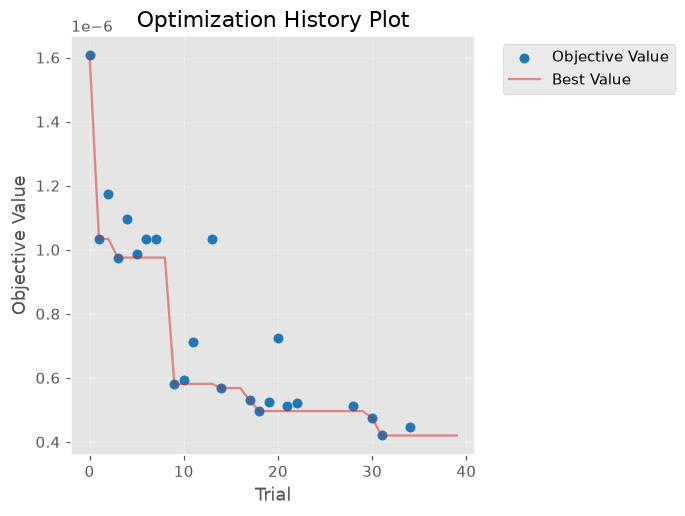

/tmp/ipykernel_27497/4065130536.py:18: ExperimentalWarning: plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study);    plt.tight_layout(); plt.savefig(LOCAL_DIR / "plots" / "optuna_importances.png", dpi=150); plt.show()


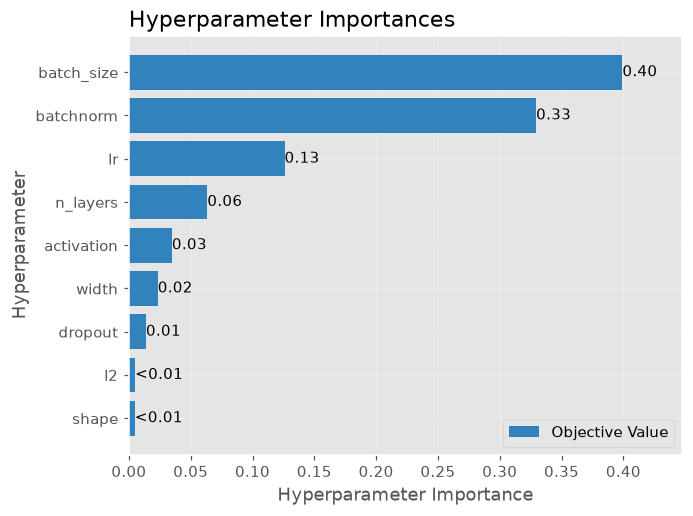

Melhores hiperparâmetros: {
  "n_layers": 2,
  "width": 64,
  "shape": "funnel",
  "activation": "relu",
  "dropout": 0.0,
  "l2": 1.293278334878133e-08,
  "lr": 0.002787485976760782,
  "batch_size": 2048,
  "batchnorm": true
}


Model: "pNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features_e_kl (InputLayer)      │ (None, 57)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         3,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probs (Dense)                   │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,275 (24.51 KB)

 Trainable params: 6,083 (23.76 KB)

 Non-trainable params: 192 (768.00 B)

In [25]:
if RUN_OPTUNA:
    COMPLETE = optuna.trial.TrialState.COMPLETE
    assert any(t.state == COMPLETE for t in study.trials), "Nenhuma tentativa terminou: aumente OPTUNA_TRIALS / OPTUNA_TIMEOUT"

    df_t = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs"))
    df_t = df_t.sort_values("value")
    display(df_t.head(10))
    print(df_t["state"].value_counts().to_dict())
    df_t.to_csv(LOCAL_DIR / "optuna_trials.csv", index=False)

    # val_loss da configuração inicial (tentativa 0) vs. a melhor
    t0_val = study.trials[0].value
    print(f"val_loss (subconjunto): inicial = {t0_val:.5f} | melhor = {study.best_value:.5f}  (tentativa #{study.best_trial.number})")

    try:
        from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
        plot_optimization_history(study); plt.tight_layout(); plt.savefig(LOCAL_DIR / "plots" / "optuna_history.png", dpi=150); plt.show()
        plot_param_importances(study);    plt.tight_layout(); plt.savefig(LOCAL_DIR / "plots" / "optuna_importances.png", dpi=150); plt.show()
    except Exception as e:
        print("[aviso] não consegui plotar os gráficos do Optuna:", e)

    best = study.best_params
    OPTUNA_BEST = dict(params=best, val_loss_subset=study.best_value, n_trials=len(study.trials))
    (LOCAL_DIR / "optuna_best.json").write_text(json.dumps(OPTUNA_BEST, indent=2, default=str))
    print("Melhores hiperparâmetros:", json.dumps(best, indent=2))

    if APPLY_BEST:
        HIDDEN_UNITS  = hidden_from(best["n_layers"], best["width"], best["shape"])
        ACTIVATION    = best["activation"]
        DROPOUT       = best["dropout"]
        L2            = best["l2"]
        LEARNING_RATE = best["lr"]
        BATCH_SIZE    = best["batch_size"]
        USE_BATCHNORM = best["batchnorm"]
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED)
        model = compile_pnn(build_pnn(F + 1, HIDDEN_UNITS, ACTIVATION, DROPOUT, L2, USE_BATCHNORM), LEARNING_RATE)
        model.summary()
    del Xo_tr, yo_tr, wo_tr, Xo_va, yo_va, wo_va            # libera a memória do subconjunto
    sync_to_eos()
else:
    print("RUN_OPTUNA = False: o treino usa os hiperparâmetros da seção Modelo/Treino.")

### Treino final

Agora treinamos a pNN (com os melhores hiperparâmetros do Optuna, ou os iniciais se `RUN_OPTUNA = False`) no **conjunto de treino completo**, com até `EPOCHS` épocas e early stopping na validação completa.

In [26]:
class SyncToEOS(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        sync_to_eos()

callbacks = [
    keras.callbacks.ModelCheckpoint(str(LOCAL_DIR / "best.weights.h5"), monitor="val_loss",
                                    save_best_only=True, save_weights_only=True),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(2, PATIENCE // 3), min_lr=1e-6),
    keras.callbacks.CSVLogger(str(LOCAL_DIR / "history.csv")),
    SyncToEOS(),
]

if RESUME and (OUT_DIR / "best.weights.h5").exists():
    model.load_weights(str(OUT_DIR / "best.weights.h5"))
    print("Pesos carregados de", OUT_DIR / "best.weights.h5")

class MemmapSequence(keras.utils.Sequence):
    # serve batches (x, y, sample_weight) lidos de um memmap em disco
    def __init__(self, d, batch_size, shuffle, mini=16, seed=SEED):
        super().__init__()
        self.X, self.y, self.w = d["X"], d["y"], d["w_train"]
        self.n, self.bs, self.shuffle, self.mini = len(self.y), batch_size, shuffle, mini
        self.per = max(1, batch_size // mini)                    # mini-blocos por batch
        self.n_mini = int(np.ceil(self.n / mini))
        self.rng = np.random.default_rng(seed)
        self.on_epoch_end()
    def __len__(self):
        return int(np.ceil(self.n_mini / self.per))
    def on_epoch_end(self):
        self.order = self.rng.permutation(self.n_mini) if self.shuffle else np.arange(self.n_mini)
    def __getitem__(self, b):
        mb = np.sort(self.order[b * self.per:(b + 1) * self.per])             # sorted: leitura em ordem crescente no disco
        rows = (mb[:, None] * self.mini + np.arange(self.mini)).ravel()
        rows = rows[rows < self.n]
        return np.asarray(self.X[rows]), self.y[rows], self.w[rows]

tr, va = D["train"], D["val"]
tr_seq = MemmapSequence(tr, BATCH_SIZE, shuffle=True)
va_seq = MemmapSequence(va, BATCH_SIZE, shuffle=False)
history = model.fit(tr_seq, validation_data=va_seq, epochs=EPOCHS,
                    callbacks=callbacks, verbose=2)

Epoch 1/100


I0000 00:00:1792698448.135695   27497 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1792698450.517181   27636 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1206935__.29
I0000 00:00:1792698468.725409   27637 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1206935__.29
I0000 00:00:1792698499.613662   27636 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1206935__.29


12459/12459 - 68s - 5ms/step - accuracy: 0.7811 - loss: 1.5918e-07 - val_accuracy: 0.8293 - val_loss: 3.6622e-08 - learning_rate: 0.0028
Epoch 2/100
12459/12459 - 57s - 5ms/step - accuracy: 0.8340 - loss: 3.6015e-08 - val_accuracy: 0.8291 - val_loss: 3.6336e-08 - learning_rate: 0.0028
Epoch 3/100
12459/12459 - 57s - 5ms/step - accuracy: 0.8356 - loss: 3.5751e-08 - val_accuracy: 0.8425 - val_loss: 3.4769e-08 - learning_rate: 0.0028
Epoch 4/100
12459/12459 - 57s - 5ms/step - accuracy: 0.8365 - loss: 3.5611e-08 - val_accuracy: 0.8387 - val_loss: 3.5380e-08 - learning_rate: 0.0028
Epoch 5/100
12459/12459 - 57s - 5ms/step - accuracy: 0.8454 - loss: 3.3525e-08 - val_accuracy: 0.8515 - val_loss: 3.2551e-08 - learning_rate: 0.0014
Epoch 6/100
12459/12459 - 57s - 5ms/step - accuracy: 0.8461 - loss: 3.3413e-08 - val_accuracy: 0.8517 - val_loss: 3.2583e-08 - learning_rate: 0.0014
Epoch 7/100
12459/12459 - 57s - 5ms/step - accuracy: 0.8464 - loss: 3.3318e-08 - val_accuracy: 0.8504 - val_loss: 3.25

Podemos agora plotar a evolução da loss e da acurácia (ponderadas) ao longo das épocas:

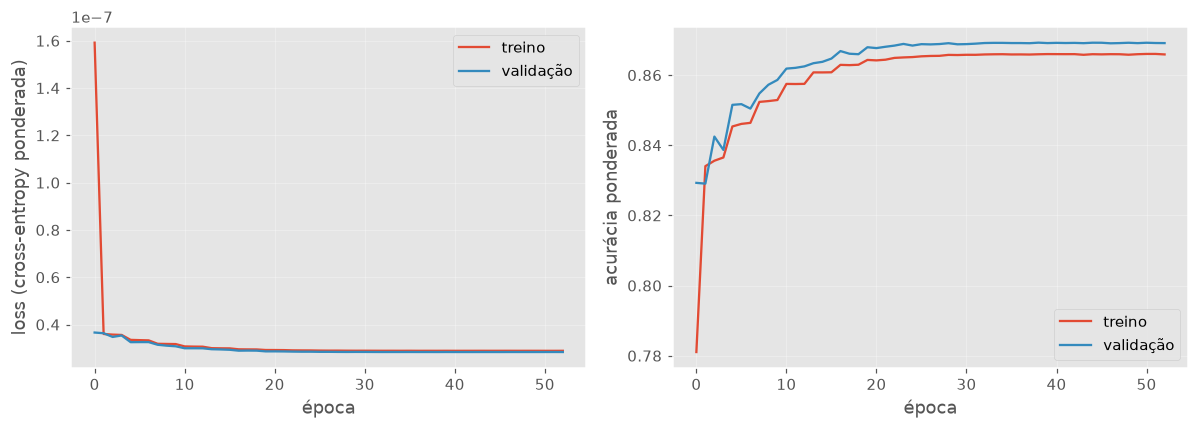

In [27]:
h = history.history
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(h["loss"], label="treino"); axes[0].plot(h["val_loss"], label="validação")
axes[0].set_xlabel("época"); axes[0].set_ylabel("loss (cross-entropy ponderada)"); axes[0].legend()
if "accuracy" in h:
    axes[1].plot(h["accuracy"], label="treino"); axes[1].plot(h["val_accuracy"], label="validação")
    axes[1].set_xlabel("época"); axes[1].set_ylabel("acurácia ponderada"); axes[1].legend()
fig.tight_layout(); fig.savefig(LOCAL_DIR / "plots" / "treino.png", dpi=150); plt.show()

## Avaliação

Para cada hipótese `kl_h` trocamos a **última coluna** de `X_teste` pelo mesmo valor em todos os eventos, e calculamos o score `p(HH)`.

- **Matriz de AUC** e **curvas ROC**: linhas = $\kappa_\lambda$ verdadeiro da amostra de sinal, colunas = $\kappa_\lambda$ usado como entrada. AUC de HH contra DY+TT.
  Espera-se o melhor desempenho perto da diagonal (hipótese = verdade) e variação suave entre as colunas.
- **Score vs kl_h**: o score médio do sinal de cada amostra deve variar de forma suave com `kl_h` (é isso que "interpolar" significa numa pNN), e o do fundo deve ficar baixo.

`KL_SCAN` são as hipóteses testadas; a lista se une aos $\kappa_\lambda$ presentes no teste. Note que 0.5, 1.5, 3 e 4 **não** existem no MC de treino.

> **Peso usado aqui:** `w_eval = te["w_phys"]` é o `normalization_weight` oficial **com sinal** (sem corte em 0; o treino usa a versão renormalizada, mas as métricas abaixo são invariantes a essa escala). Ele é usado como está nos histogramas de score e no score médio vs `kl_h`, então bins e pontos podem, em princípio, ficar negativos — isso é esperado quando eventos de peso negativo dominam aquele bin, e reflete o cancelamento real do gerador.
> Para a **AUC e a curva ROC**, o `roc_auc_score`/`roc_curve` do scikit-learn exigem pesos não-negativos (a conta internamente assume que somar mais um evento só pode aumentar TPR/FPR); pesos negativos quebram essa suposição e geram uma "curva" não-monótona. Por isso, só nessas duas métricas usamos `w_auc = np.abs(w_eval)`. Isso é uma limitação da métrica, não uma escolha de física: o valor absoluto ainda dá a cada evento seu peso físico correto, só perde a informação de sinal na hora de rankear.

In [28]:
# ============================ Avaliação ============================
KL_SCAN = [0, 0.5, 1, 1.5, 2, 2.45, 3, 4, 5]   # hipóteses de kl testadas (une-se aos kl do MC)

In [29]:
def predict_chunked(model, Xmat, kl=None, chunk=CHUNK_SIZE):
    # prediz em chunks lendo do memmap; se kl for dado, ele vira a última coluna de todos os eventos
    out = np.empty((len(Xmat), 3), np.float32)
    for i in range(0, len(Xmat), chunk):
        xb = np.array(Xmat[i:i + chunk], dtype=np.float32)       # copia o chunk para a RAM
        if kl is not None:
            xb[:, -1] = kl_norm(kl)
        out[i:i + len(xb)] = model.predict(xb, batch_size=65536, verbose=0)
    return out

te = D["test"]
te_kls = np.unique(te["kl_true"][te["y"] == 2])
KL_GRID = sorted({round(float(k), 6) for k in list(KL_SCAN) + list(te_kls)})

P = {}                                    # kl_h -> probabilidades (N, 3)
for k in KL_GRID:
    P[k] = predict_chunked(model, te["X"], kl=k)     # mesma hipótese para todos os eventos
    print(f"kl_h = {k:g}: ok")

kl_h = 0: ok
kl_h = 0.5: ok
kl_h = 1: ok
kl_h = 1.5: ok
kl_h = 2: ok
kl_h = 2.45: ok
kl_h = 3: ok
kl_h = 4: ok
kl_h = 5: ok


Agora a **matriz de AUC**: para cada amostra de sinal (linha) e cada hipótese de $\kappa_\lambda$ (coluna), a AUC de HH contra DY+TT, ponderada por `weight`:

In [30]:
w_eval = te["w_train"]           # peso físico com sinal (histogramas, score médio)
w_auc  = np.abs(w_eval)         # roc_auc_score/roc_curve exigem peso não-negativo (ver nota acima)
is_bkg = te["y"] != 2

auc = np.full((len(te_kls), len(KL_GRID)), np.nan)
for i, kt in enumerate(te_kls):
    m = is_bkg | ((te["y"] == 2) & np.isclose(te["kl_true"], kt))     # amostra de sinal kt + todos os fundos
    yt = (te["y"][m] == 2).astype(int)
    for j, kh in enumerate(KL_GRID):
        auc[i, j] = roc_auc_score(yt, P[kh][m, 2], sample_weight=w_auc[m])

row_labels = [f"kl={k:g}" + ("  (holdout)" if not np.isclose(k, TRAIN_KL).any() else "") for k in te_kls]
AUC = pd.DataFrame(auc, index=row_labels, columns=[f"{k:g}" for k in KL_GRID])
AUC.index.name, AUC.columns.name = "kl verdadeiro", "kl hipótese"
display(AUC.style.format("{:.4f}").background_gradient(axis=None, cmap="viridis"))
AUC.to_csv(LOCAL_DIR / "auc_matrix.csv")

kl hipótese,0,0.5,1,1.5,2,2.45,3,4,5
kl verdadeiro,,,,,,,,,
kl=0,0.9584,0.9583,0.9579,0.9574,0.9562,0.9550,0.9545,0.9535,0.9514
kl=1,0.9669,0.9670,0.9669,0.9665,0.9652,0.9636,0.9620,0.9591,0.9560
kl=2.45,0.9615,0.9616,0.9618,0.9624,0.9634,0.9640,0.9640,0.9615,0.9580
kl=5,0.9105,0.9091,0.9081,0.9087,0.9121,0.9167,0.9240,0.9318,0.9344


Vejamos agora as distribuições do score $p(\mathrm{HH})$ (com $\kappa_\lambda^h$ igual ao verdadeiro) e as curvas ROC, em escala logarítmica:

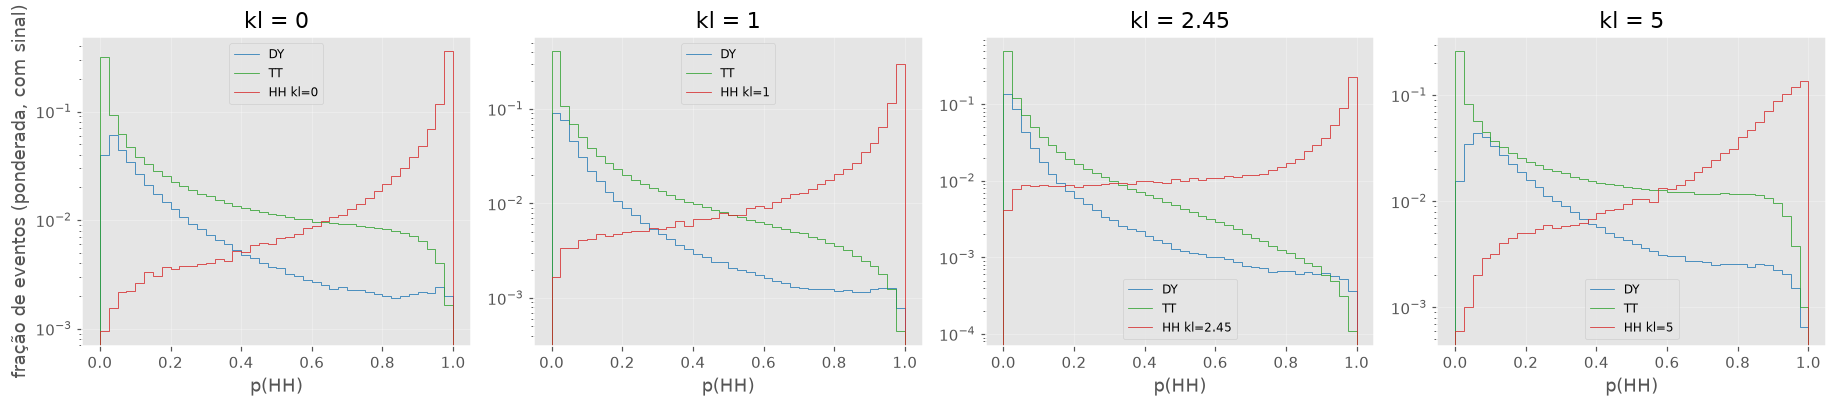

/tmp/ipykernel_27497/1491798496.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout(); fig.savefig(LOCAL_DIR / "plots" / "roc.png", dpi=150); plt.show()
/cvmfs/sft.cern.ch/lcg/views/LCG_110_cuda/x86_64-el9-gcc13-opt/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


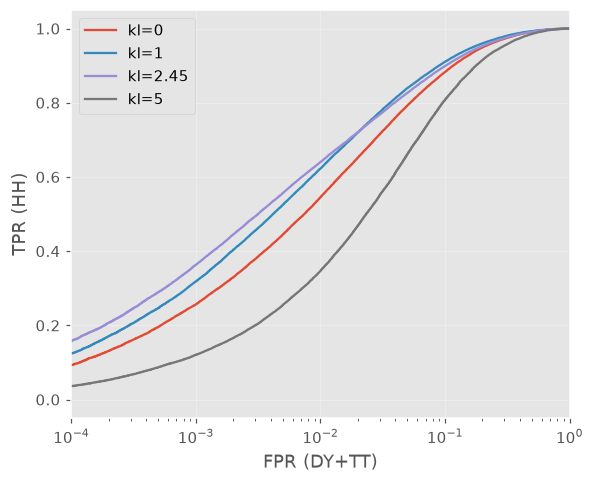

In [31]:
# ---------- distribuições do score p(HH) (kl_h = kl verdadeiro) ----------
n = len(te_kls)
fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 3.8), squeeze=False)
bins = np.linspace(0, 1, 41)

def hist_norm(ax, s, w, label, **kw):
    hh, _ = np.histogram(s, bins=bins, weights=w)
    norm = np.abs(w).sum()                       # normaliza pela soma dos |peso| (estável a cancelamento)
    ax.stairs(hh / max(norm, 1e-30), bins, label=label, **kw)    # bins podem ficar negativos (peso com sinal)

for ax, kt in zip(axes[0], te_kls):
    p = P[round(float(kt), 6)][:, 2]
    for c, col in ((0, "tab:blue"), (1, "tab:green")):
        s = te["y"] == c
        hist_norm(ax, p[s], w_eval[s], CLASS_NAMES[c], color=col)
    s = (te["y"] == 2) & np.isclose(te["kl_true"], kt)
    hist_norm(ax, p[s], w_eval[s], f"HH kl={kt:g}", color="tab:red")
    ax.set_yscale("log"); ax.set_xlabel("p(HH)"); ax.set_title(f"kl = {kt:g}"); ax.legend(fontsize=8)
axes[0][0].set_ylabel("fração de eventos (ponderada, com sinal)")
fig.tight_layout(); fig.savefig(LOCAL_DIR / "plots" / "scores.png", dpi=150); plt.show()

# ---------- curvas ROC ----------
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for kt in te_kls:
    m = is_bkg | ((te["y"] == 2) & np.isclose(te["kl_true"], kt))
    yt = (te["y"][m] == 2).astype(int)
    fpr, tpr, _ = roc_curve(yt, P[round(float(kt), 6)][m, 2], sample_weight=w_auc[m])
    ax.plot(fpr, tpr, label=f"kl={kt:g}")
ax.set_xscale("log"); ax.set_xlim(1e-4, 1); ax.set_xlabel("FPR (DY+TT)"); ax.set_ylabel("TPR (HH)"); ax.legend()
fig.tight_layout(); fig.savefig(LOCAL_DIR / "plots" / "roc.png", dpi=150); plt.show()

Os mesmos gráficos em escala linear (salvos como `scores_linear.png` e `roc_linear.png`):

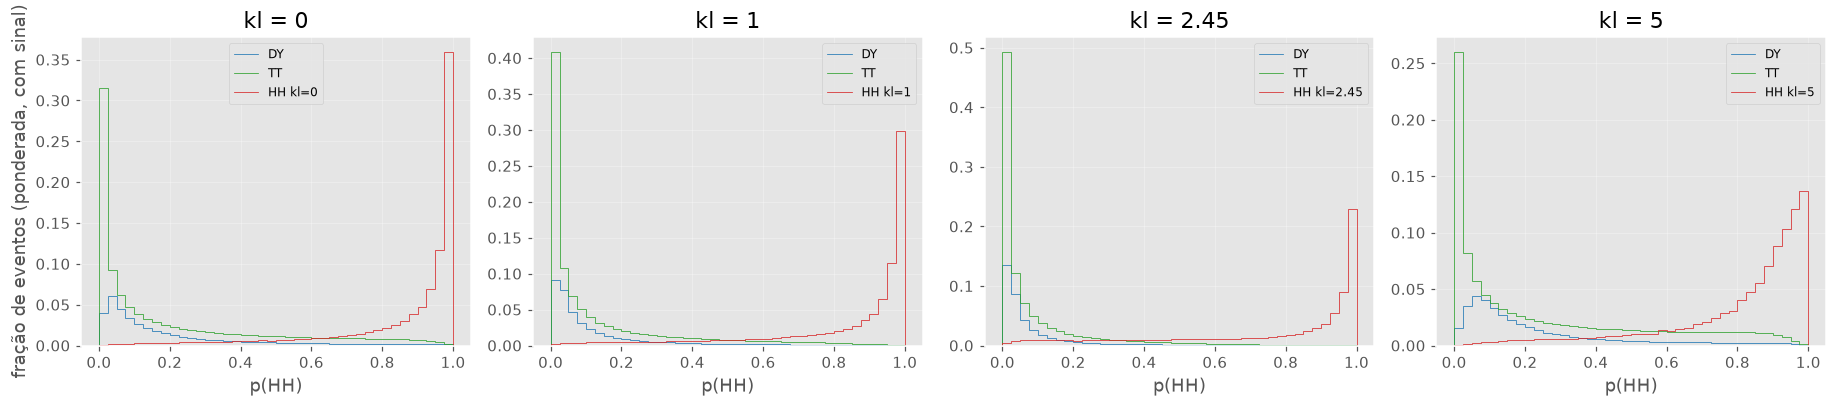

/tmp/ipykernel_27497/3481998668.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout(); fig.savefig(LOCAL_DIR / "plots" / "roc_linear.png", dpi=150); plt.show()
/cvmfs/sft.cern.ch/lcg/views/LCG_110_cuda/x86_64-el9-gcc13-opt/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


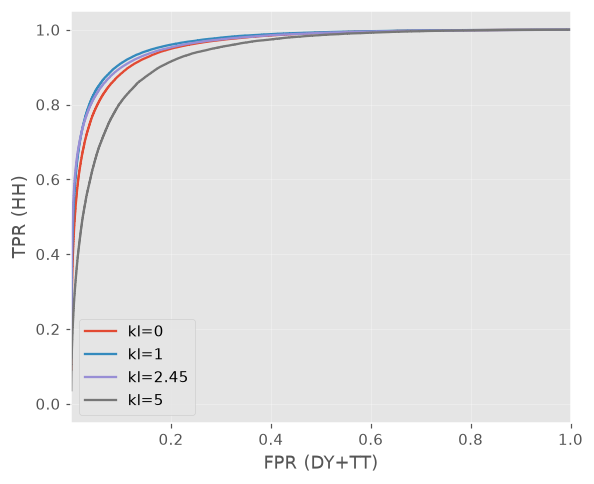

In [32]:
# ---------- distribuições do score p(HH) (kl_h = kl verdadeiro) ----------
n = len(te_kls)
fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 3.8), squeeze=False)
bins = np.linspace(0, 1, 41)

def hist_norm(ax, s, w, label, **kw):
    hh, _ = np.histogram(s, bins=bins, weights=w)
    norm = np.abs(w).sum()                       # normaliza pela soma dos |peso| (estável a cancelamento)
    ax.stairs(hh / max(norm, 1e-30), bins, label=label, **kw)    # bins podem ficar negativos (peso com sinal)

for ax, kt in zip(axes[0], te_kls):
    p = P[round(float(kt), 6)][:, 2]
    for c, col in ((0, "tab:blue"), (1, "tab:green")):
        s = te["y"] == c
        hist_norm(ax, p[s], w_eval[s], CLASS_NAMES[c], color=col)
    s = (te["y"] == 2) & np.isclose(te["kl_true"], kt)
    hist_norm(ax, p[s], w_eval[s], f"HH kl={kt:g}", color="tab:red")
    ax.set_xlabel("p(HH)"); ax.set_title(f"kl = {kt:g}"); ax.legend(fontsize=8)
axes[0][0].set_ylabel("fração de eventos (ponderada, com sinal)")
fig.tight_layout(); fig.savefig(LOCAL_DIR / "plots" / "scores_linear.png", dpi=150); plt.show()

# ---------- curvas ROC ----------
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for kt in te_kls:
    m = is_bkg | ((te["y"] == 2) & np.isclose(te["kl_true"], kt))
    yt = (te["y"][m] == 2).astype(int)
    fpr, tpr, _ = roc_curve(yt, P[round(float(kt), 6)][m, 2], sample_weight=w_auc[m])
    ax.plot(fpr, tpr, label=f"kl={kt:g}")
ax.set_xlim(1e-4, 1); ax.set_xlabel("FPR (DY+TT)"); ax.set_ylabel("TPR (HH)"); ax.legend()
fig.tight_layout(); fig.savefig(LOCAL_DIR / "plots" / "roc_linear.png", dpi=150); plt.show()

/tmp/ipykernel_27497/2524179416.py:32: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout(); fig.savefig(LOCAL_DIR / "plots" / "recall.png", dpi=150); plt.show()
/cvmfs/sft.cern.ch/lcg/views/LCG_110_cuda/x86_64-el9-gcc13-opt/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


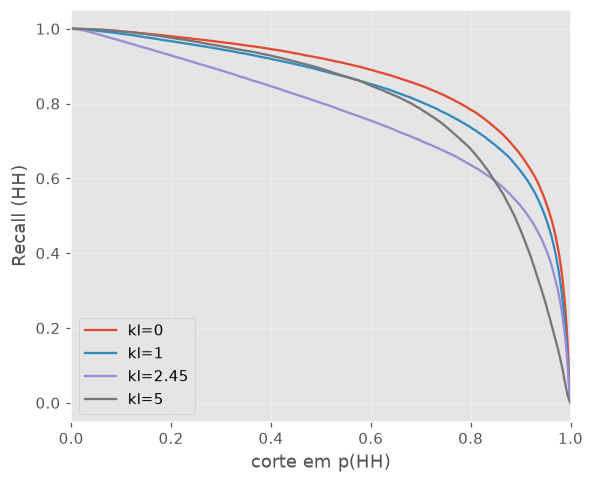

/tmp/ipykernel_27497/2524179416.py:39: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout(); fig.savefig(LOCAL_DIR / "plots" / "precision.png", dpi=150); plt.show()


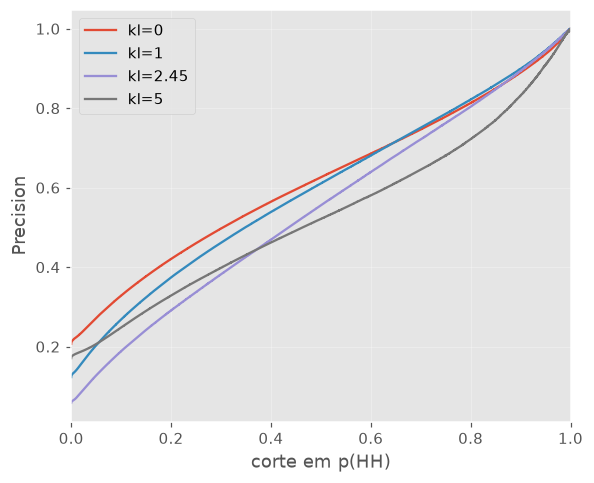

In [33]:
# ---------- Recall e Precision em função do corte em p(HH) (kl_h = kl verdadeiro) ----------
from sklearn.metrics import precision_recall_curve

# "phys"  -> normalization_weight oficial; "train" -> pesos renormalizados (sinal soma 1, fundo soma 1)
PR_WEIGHT = "train"
w_pr = np.abs(te["w_phys"] if PR_WEIGHT == "phys" else te["w_train"].astype(np.float64))   # sklearn exige peso >= 0

CUTS = [0.5, 0.8, 0.9, 0.95, 0.99]     # cortes em p(HH) para a tabela

curvas, linhas = {}, []
for kt in te_kls:
    m  = is_bkg | ((te["y"] == 2) & np.isclose(te["kl_true"], kt))     # amostra de sinal kt + todos os fundos
    yt = (te["y"][m] == 2).astype(int)
    sc = P[round(float(kt), 6)][m, 2]
    w  = w_pr[m]

    prec, rec, thr = precision_recall_curve(yt, sc, sample_weight=w)
    curvas[kt] = (thr, prec[:-1], rec[:-1])                            # prec/rec têm 1 ponto a mais que thr

    for t in CUTS:                                                     # tabela em cortes fixos
        passa, sig = sc >= t, yt == 1
        tp, fp = w[passa & sig].sum(), w[passa & ~sig].sum()
        linhas.append(dict(kl=kt, corte=t,
                           recall=tp / w[sig].sum(),
                           precision=tp / (tp + fp) if (tp + fp) > 0 else np.nan))

# ---------- Recall ----------
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for kt, (thr, prec, rec) in curvas.items():
    ax.plot(thr, rec, label=f"kl={kt:g}")
ax.set_xlim(0, 1); ax.set_xlabel("corte em p(HH)"); ax.set_ylabel("Recall (HH)"); ax.legend()
fig.tight_layout(); fig.savefig(LOCAL_DIR / "plots" / "recall.png", dpi=150); plt.show()

# ---------- Precision ----------
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for kt, (thr, prec, rec) in curvas.items():
    ax.plot(thr, prec, label=f"kl={kt:g}")
ax.set_xlim(0, 1); ax.set_xlabel("corte em p(HH)"); ax.set_ylabel("Precision"); ax.legend()
fig.tight_layout(); fig.savefig(LOCAL_DIR / "plots" / "precision.png", dpi=150); plt.show()

# ---------- Tabela (recall e precision em cortes fixos) ----------
tab_pr = pd.DataFrame(linhas)
display(tab_pr.pivot(index="kl", columns="corte", values=["recall", "precision"]).style.format("{:.4f}"))
tab_pr.to_csv(LOCAL_DIR / "precision_recall_table.csv", index=False)

Por fim, a matriz de AUC como imagem e o **score médio de $p(\mathrm{HH})$ em função de $\kappa_\lambda^h$**. Se a pNN interpola bem, essas curvas devem variar de forma suave, e a dos fundos deve ficar baixa:

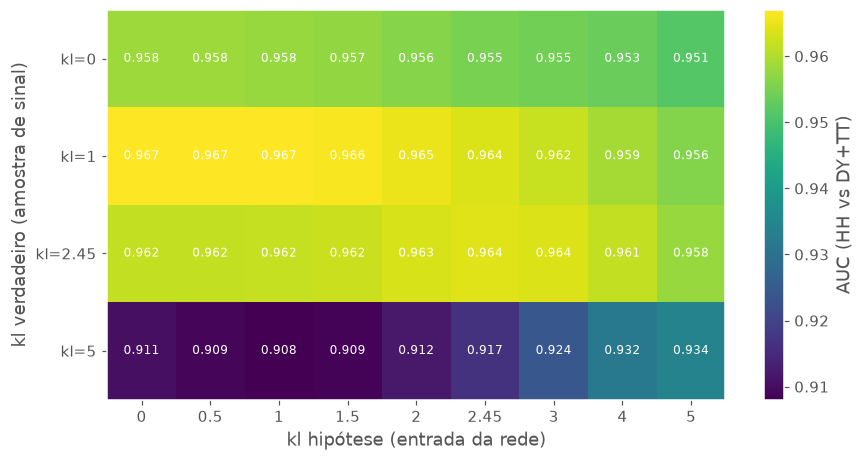

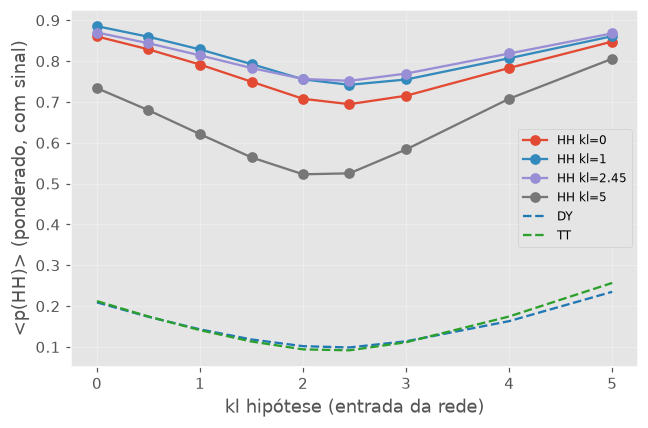

In [34]:
# ---------- matriz de AUC ----------
fig, ax = plt.subplots(figsize=(1 + 0.8 * len(KL_GRID), 1.5 + 0.7 * len(te_kls)))
im = ax.imshow(AUC.values, cmap="viridis", aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(KL_GRID))); ax.set_xticklabels(AUC.columns)
ax.set_yticks(range(len(te_kls))); ax.set_yticklabels(AUC.index)
ax.set_xlabel("kl hipótese (entrada da rede)"); ax.set_ylabel("kl verdadeiro (amostra de sinal)")
for i in range(AUC.shape[0]):
    for j in range(AUC.shape[1]):
        ax.text(j, i, f"{AUC.values[i, j]:.3f}", ha="center", va="center", color="w", fontsize=8)
fig.colorbar(im, ax=ax, label="AUC (HH vs DY+TT)")
fig.tight_layout(); fig.savefig(LOCAL_DIR / "plots" / "auc_matrix.png", dpi=150); plt.show()

# ---------- score médio de p(HH) em função de kl_h (peso físico com sinal) ----------
fig, ax = plt.subplots(figsize=(6, 4))
for kt in te_kls:
    s = (te["y"] == 2) & np.isclose(te["kl_true"], kt)
    ax.plot(KL_GRID, [np.average(P[k][s, 2], weights=w_eval[s]) for k in KL_GRID], marker="o", label=f"HH kl={kt:g}")
for c, col in ((0, "tab:blue"), (1, "tab:green")):
    s = te["y"] == c
    ax.plot(KL_GRID, [np.average(P[k][s, 2], weights=w_eval[s]) for k in KL_GRID], "--", color=col, label=CLASS_NAMES[c])
ax.set_xlabel("kl hipótese (entrada da rede)"); ax.set_ylabel("<p(HH)> (ponderado, com sinal)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(LOCAL_DIR / "plots" / "score_vs_kl.png", dpi=150); plt.show()

> Os números e a leitura acima (parágrafo de comentário do run salvo) foram feitos com o corte em 0 dos pesos negativos. Com os pesos físicos completos os valores de AUC e de $\langle p(\mathrm{HH}) \rangle$ vão mudar um pouco — rode o notebook de novo e atualize este parágrafo com os novos números.

## Correlação e importância das features

Duas análises extras sobre o conjunto de teste:

- **Correlação de Pearson** entre as features padronizadas (o $\kappa_\lambda$, última coluna, fica de fora). Muitas features são componentes de quadrivetores e de sistemas compostos (por exemplo `htt` é a soma dos dois taus), então é esperado ver blocos correlacionados.
- **Permutation importance**: embaralhamos uma feature por vez e medimos a queda na acurácia. Quanto maior a queda, mais a rede depende daquela feature. O $\kappa_\lambda$ de cada evento é mantido como no teste (o verdadeiro no sinal, o sorteado no fundo).

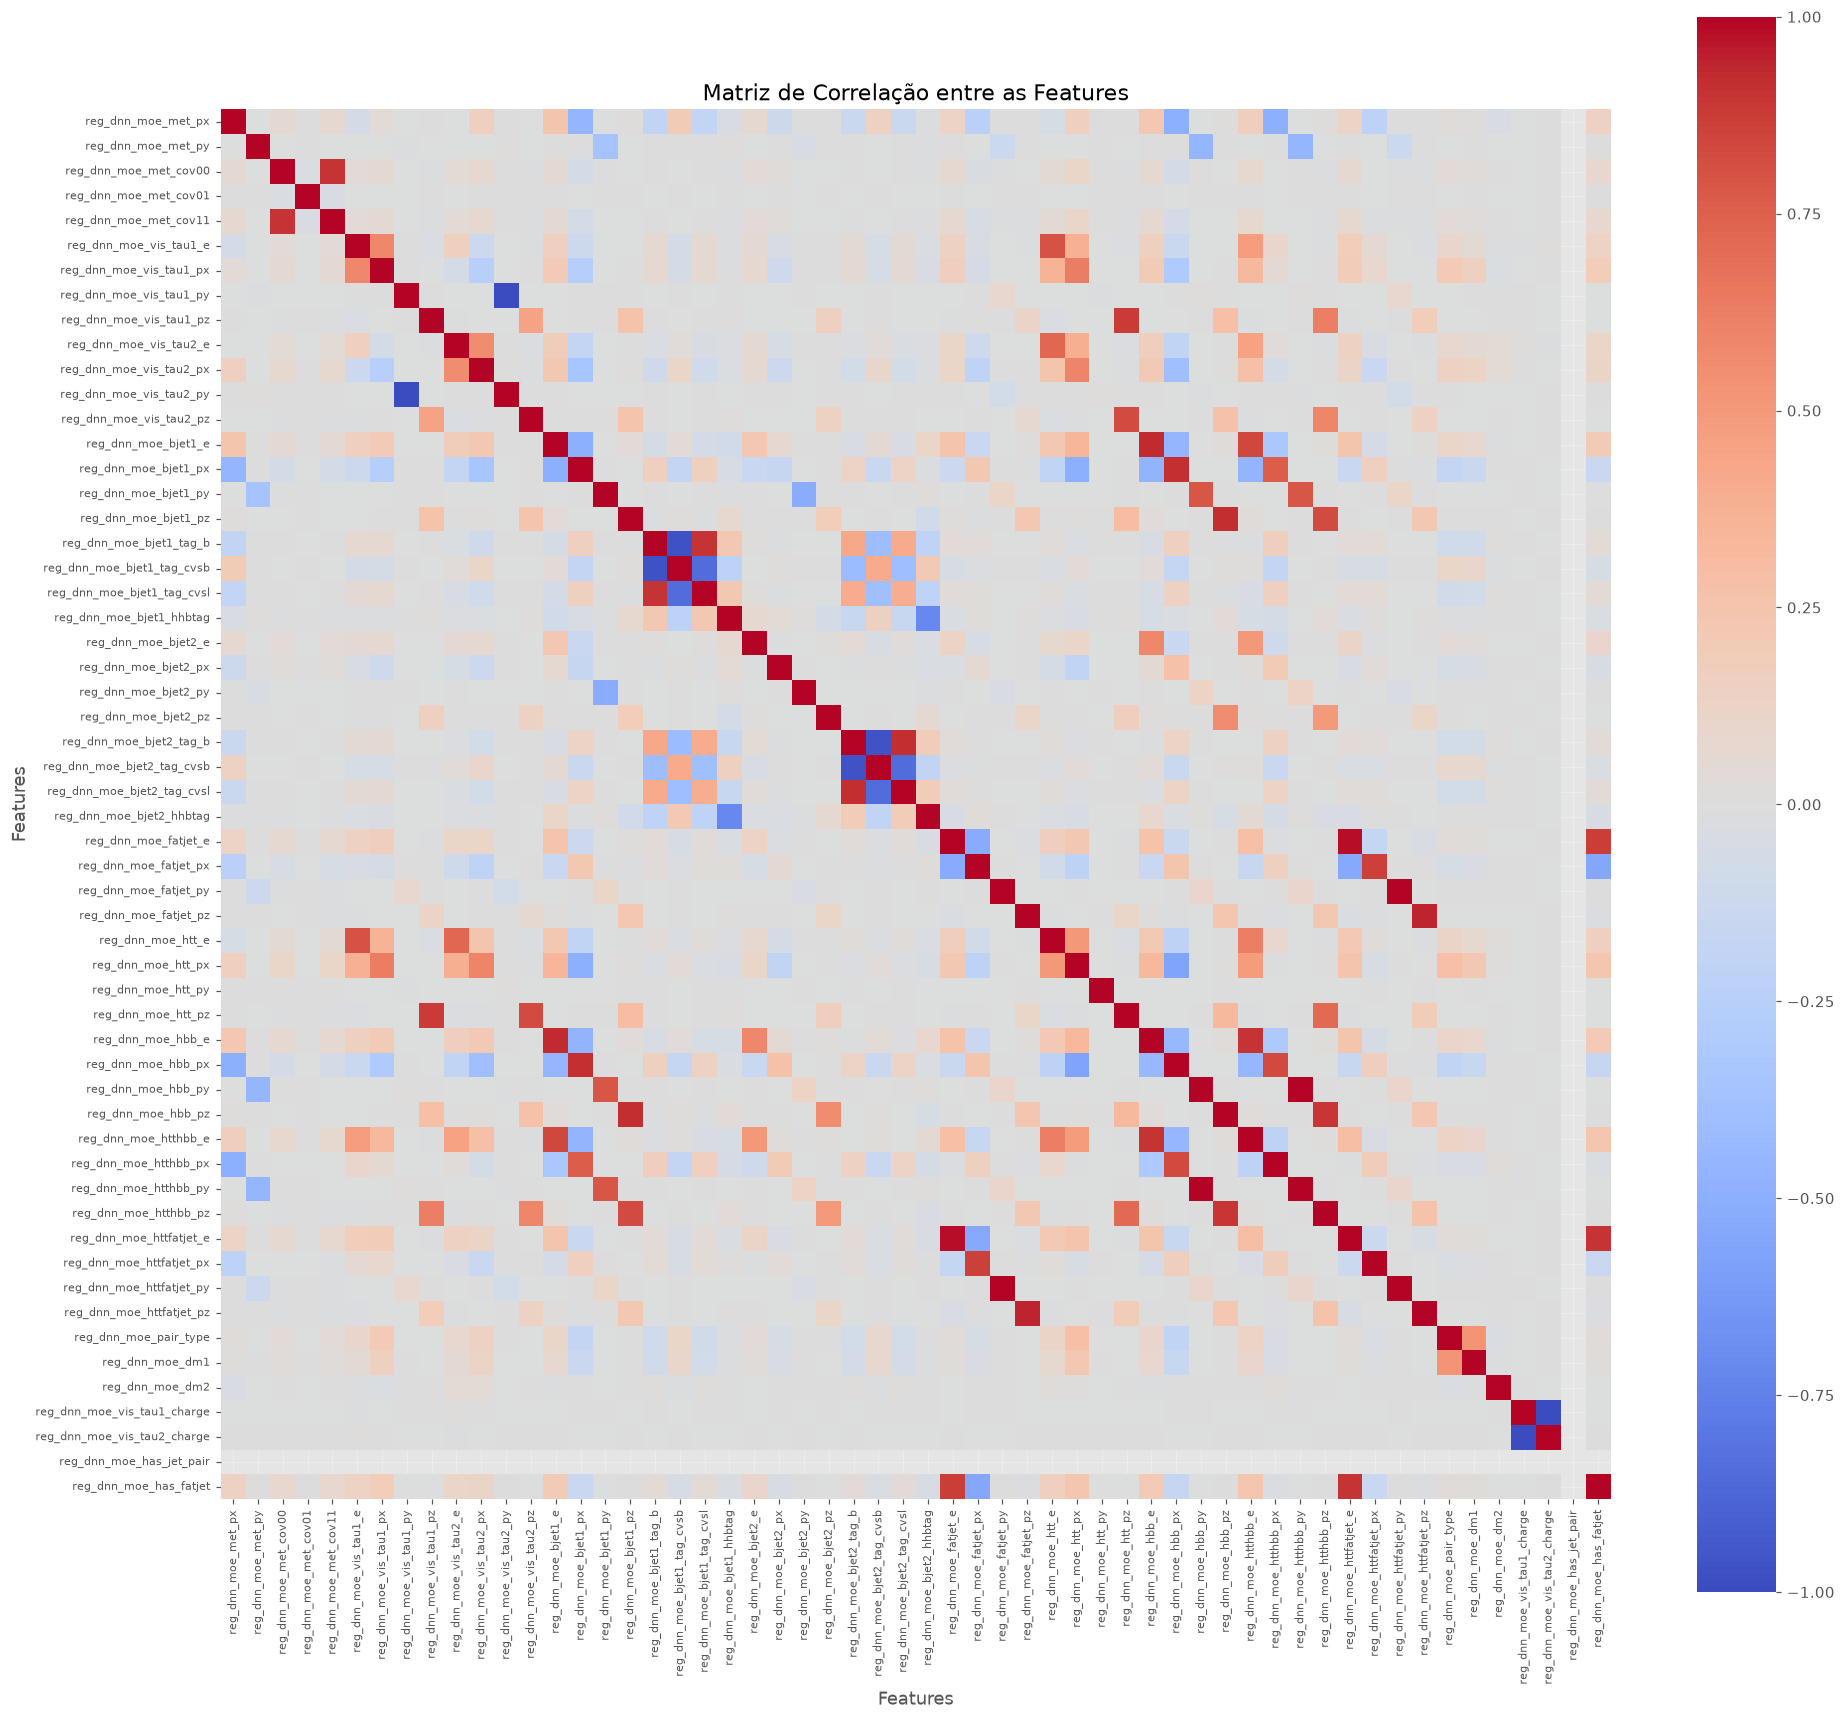

In [35]:
# Usar o conjunto de teste
# A última coluna é kappa_lambda, portanto não entra na correlação
# (subamostra de até 500 mil eventos do teste, lida do disco: basta para a correlação e evita carregar tudo)
_n = len(D["test"]["y"])
_sel = np.sort(np.random.default_rng(SEED).choice(_n, min(500_000, _n), replace=False))
X_corr = np.asarray(D["test"]["X"][_sel, :F])

# Criar DataFrame usando os nomes das FEATURES
df_corr = pd.DataFrame(
    X_corr,
    columns=FEATURES
)

# Matriz de correlação de Pearson
corr = df_corr.corr()

# Plot
plt.figure(figsize=(18, 16))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    xticklabels=FEATURES,
    yticklabels=FEATURES
)

plt.title("Matriz de Correlação entre as Features")
plt.xlabel("Features")
plt.ylabel("Features")

plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)

plt.tight_layout()
plt.show()

Acurácia original: 0.8294


,feature,importance
18,reg_dnn_moe_bjet1_tag_cvsb,0.059720
12,reg_dnn_moe_vis_tau2_pz,0.054371
8,reg_dnn_moe_vis_tau1_pz,0.047325
0,reg_dnn_moe_met_px,0.046393
19,reg_dnn_moe_bjet1_tag_cvsl,0.043325
1,reg_dnn_moe_met_py,0.036293
10,reg_dnn_moe_vis_tau2_px,0.032428
36,reg_dnn_moe_htt_pz,0.030615
25,reg_dnn_moe_bjet2_tag_b,0.029486
6,reg_dnn_moe_vis_tau1_px,0.025325


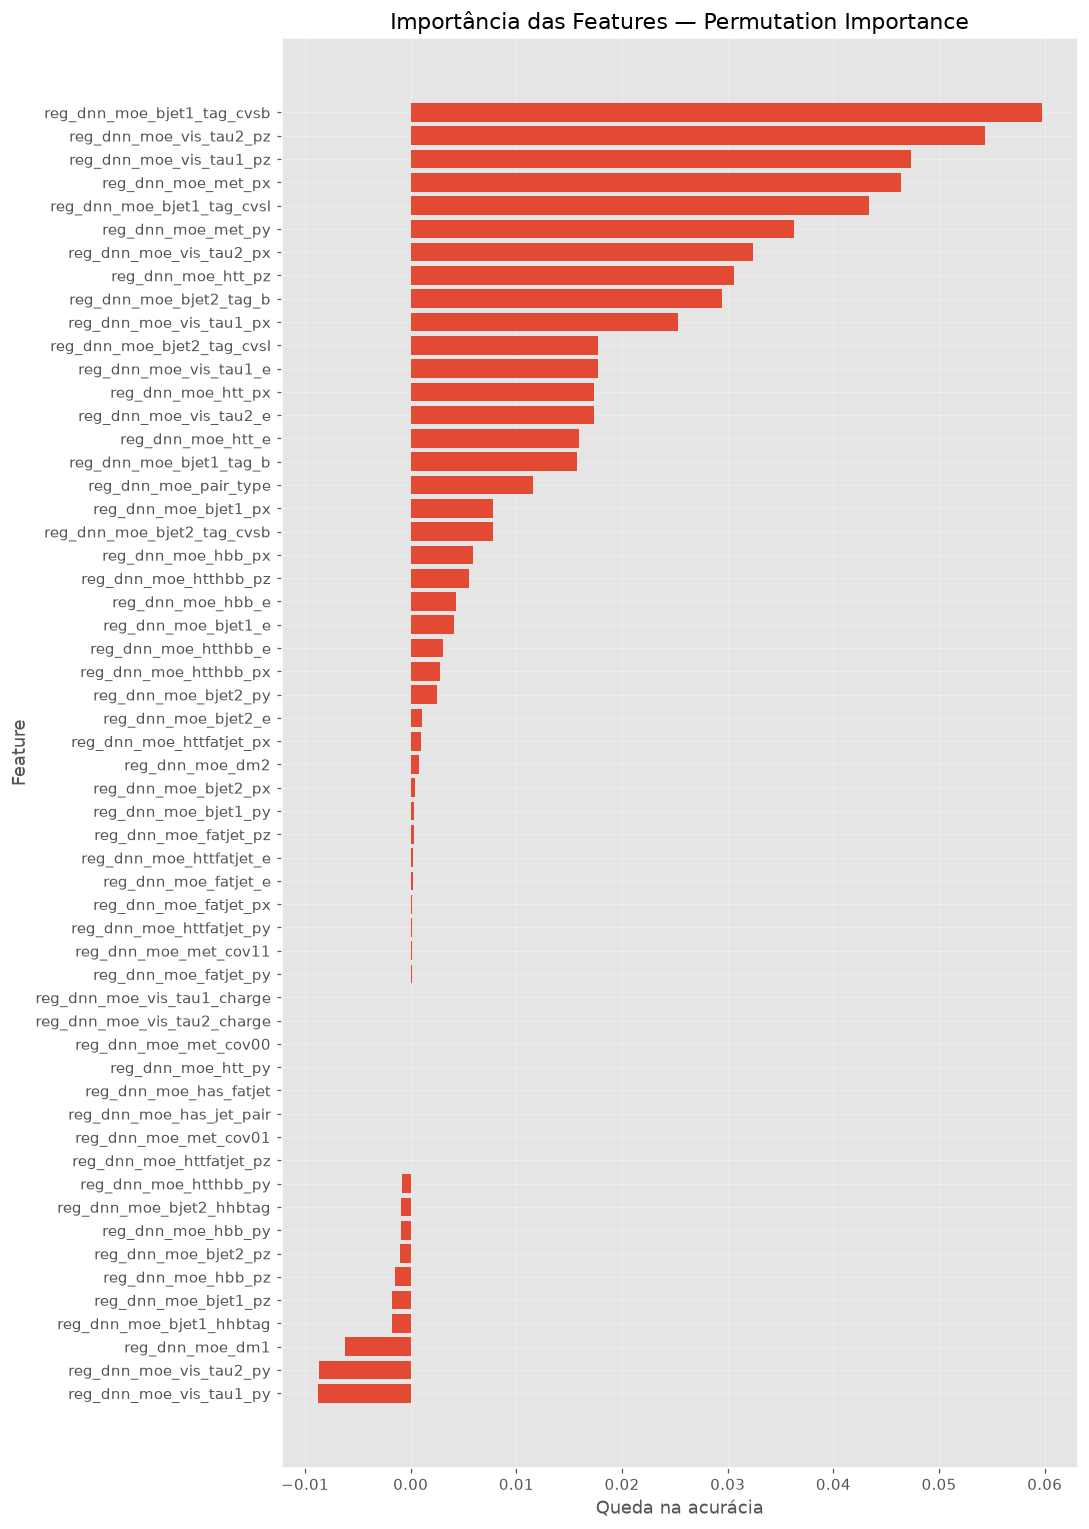

In [36]:
# κλ usado para avaliar a importância
KL_IMPORTANCE = 1.0

# Dados de teste
te = D["test"]

# subamostra do teste (lida do disco): a permutation importance faz F+1 predições, então não usamos o teste inteiro
PERM_MAX_EVENTS = 1_000_000
_n = len(te["y"])
_sel = np.sort(np.random.default_rng(SEED).choice(_n, min(PERM_MAX_EVENTS, _n), replace=False))
X_base = np.asarray(te["X"][_sel])
y_true = te["y"][_sel]

# Predição original
probs_original = model.predict(
    X_base,
    batch_size=65536,
    verbose=0
)

y_pred_original = np.argmax(probs_original, axis=1)

# Acurácia original
acc_original = np.mean(y_pred_original == y_true)

print(f"Acurácia original: {acc_original:.4f}")

# ------------------------------------------------------------
# Permutation Feature Importance
# ------------------------------------------------------------

rng = np.random.default_rng(42)

importance = []

for i, feature in enumerate(FEATURES):

    # Copiar os dados
    X_perm = X_base.copy()

    # Embaralhar somente a feature i
    X_perm[:, i] = rng.permutation(X_perm[:, i])

    # Previsão com a feature embaralhada
    probs_perm = model.predict(
        X_perm,
        batch_size=65536,
        verbose=0
    )

    y_pred_perm = np.argmax(probs_perm, axis=1)

    # Nova acurácia
    acc_perm = np.mean(y_pred_perm == y_true)

    # Queda de desempenho
    delta = acc_original - acc_perm

    importance.append(delta)

# ------------------------------------------------------------
# Organizar resultados
# ------------------------------------------------------------

importance_df = pd.DataFrame({
    "feature": FEATURES,
    "importance": importance
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

# Mostrar tabela
display(importance_df)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 14))

plt.barh(
    importance_df["feature"],
    importance_df["importance"]
)

plt.xlabel("Queda na acurácia")
plt.ylabel("Feature")
plt.title("Importância das Features — Permutation Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

No run guardado as features mais importantes são as componentes $p_z$ dos dois taus visíveis, `met_px`, e a energia e o $p_z$ do sistema `htt`; as covariâncias da MET e `has_jet_pair` têm importância praticamente nula. Ressalvas: features correlacionadas dividem a importância entre si (embaralhar uma só é parcialmente compensado pelas outras), então uma importância baixa não significa que a informação seja inútil.

## Salvando o modelo

Guardamos o modelo, a normalização (indispensável para usar o modelo depois), a configuração, a tabela de AUC e as figuras.

In [ ]:
'''
np.savez(LOCAL_DIR / "normalization.npz", mean=MEAN, std=STD, features=np.array(FEATURES),
         kl_mean=KL_MEAN, kl_std=KL_STD)
config = dict(run_name=RUN_NAME, features=FEATURES, int_features=INT_FEATURES, hidden_units=HIDDEN_UNITS,
              activation=ACTIVATION, dropout=DROPOUT, l2=L2, batchnorm=USE_BATCHNORM, optuna_best=OPTUNA_BEST, train_kl=TRAIN_KL.tolist(), holdout_kl=list(HOLDOUT_KL),
              kl_mean=KL_MEAN, kl_std=KL_STD, class_names=CLASS_NAMES, weight_column="normalization_weight", weight_norm=dict(sum_signal=1, sum_background=1, S_sig_train=S_SIG, S_bkg_train=S_BKG, loss_scale=LOSS_SCALE),
              split=SPLIT, seed=SEED, max_bkg_per_file=MAX_BKG_PER_FILE, chunk_size=CHUNK_SIZE, missing_values=MISSING_VALUES,
              batch_size=BATCH_SIZE, lr=LEARNING_RATE, epochs_run=len(history.history["loss"]),
              best_val_loss=float(np.min(history.history["val_loss"])))
(LOCAL_DIR / "config.json").write_text(json.dumps(config, indent=2, default=str))
inv.to_csv(LOCAL_DIR / "file_summary.csv", index=False)
feat_summary.to_csv(LOCAL_DIR / "feature_summary_train.csv")

try:
    model.save(str(LOCAL_DIR / "model.keras"))
except Exception as e:
    print("[aviso] model.save falhou, salvando só os pesos:", e)
model.save_weights(str(LOCAL_DIR / "model.weights.h5"))

sync_to_eos()
print("Salvo em:", OUT_DIR)
print(sorted(p.name for p in OUT_DIR.iterdir()) if OUT_DIR.exists() else "(pasta EOS não criada)")
'''

## Usar o modelo treinado

Para aplicar a pNN a dados novos (brutos, sem padronizar) num $\kappa_\lambda$ qualquer:

In [ ]:
'''
def pnn_predict(df, kl, model=model, batch_size=65536):
    # df: DataFrame com as colunas FEATURES (dados brutos); kl: valor único de kappa_lambda
    x = standardize(df[FEATURES].to_numpy(np.float32))
    xin = np.concatenate([x, np.full((len(x), 1), kl_norm(kl), np.float32)], axis=1)   # [features, kl]
    return model.predict(xin, batch_size=batch_size, verbose=0)      # colunas: p(DY), p(TT), p(HH)

# exemplo: probs = pnn_predict(df_novo, kl=1.7)

# Em outra sessão:
#   model = keras.models.load_model(OUT_DIR / "model.keras")
#   norm  = np.load(OUT_DIR / "normalization.npz", allow_pickle=True)   # mean, std, kl_mean, kl_std, features
'''